# Peripersonal space and collision judgement

Run the notebook in order: later sections use results from earlier ones.

| Section | What it does |
|---|---|
| 0 | Settings, definitions and exclusion rules |
| 1 | Loads the data and applies the preregistered PPS exclusions |
| 2 | Young controls: quality control and descriptives, PPS then collision |
| 3 | Patient and matched controls: quality control and descriptives |
| 4 | Aim 1: H1, H1a, H2, H3 in the young controls |
| 5 | Aim 2: H4, H5, H6, the patient against PA002 |
| 6 | Aim 3: H7a, H7b, the two tasks together |
| 7 | Summary of the results |
| A | Appendix: sensitivity checks |

# 0. Settings, definitions and exclusion rules

## 0.1 Imports

In [1]:
%load_ext autoreload
%autoreload 2

import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm

import style
import ppsanalysis as pa
from ppsanalysis import config, figures, qc
from ppsanalysis import expectancy as ex
from ppsanalysis import bootstrap_facilitation as bf
from ppsanalysis import baseline_comparison as bc
from ppsanalysis import baseline_robustness as br
from ppsanalysis import curve_comparison as cc
from ppsanalysis import flight_timing as ft
from ppsanalysis import pps_components as pc
from ppsanalysis import pse_uncertainty as pu
from ppsanalysis import h7b_paired as paired
from ppsanalysis.stats_utils import bootstrap_mean_ci, wilcoxon_one_sided
from ppsanalysis.hypotheses import h1, h1a, h2, h3, h4, h5, h6, h7a, h7b

style.apply()
figures.apply()

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 200)

## 0.2 Settings

Settings defined in `ppsanalysis/config.py`. 

To change one, edit that script and restart the kernel.

In [2]:
FIGURE_DIR = Path(config.FIGURE_DIR)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
figures.FIGURE_DIR = config.PACKAGE_FIGURE_DIR

print("data folder     :", config.PILOT_DATA_DIR)
print("RT window (PPS) :", config.RT_MIN_MS, "to", config.RT_MAX_MS, "ms")
print("collision RTs   : outliers beyond", config.COLLISION_RT_IQR, "IQR")
print("correction      :", config.CORRECTION, "(degree", str(config.DEGREE) + ")")
print("bootstrap draws :", config.N_BOOT, " seed", config.RANDOM_SEED)
print()
print("excluded        :", config.EXCLUDED_SUBJECTS)
print("young controls  :", config.YOUNG_CONTROL_SUBJECTS)
print("classic design  :", config.CLASSIC)
print("clinical pair   :", config.PATIENT_ID, "against", config.MATCHED_CONTROL)
print()
print("dropped per analysis:")
print(pd.Series(
    {name: ", ".join(drops) or "none" for name, drops in config.GROUP_DROPS.items()}
).to_string())

data folder     : /Users/pamelavandenenden/Desktop/PPS/05_analysis/data/behavior
RT window (PPS) : 100 to 900 ms
collision RTs   : outliers beyond 3.0 IQR
correction      : expectancy_model (degree 1)
bootstrap draws : 5000  seed 123

excluded        : {'P004': 'controller fault observed during testing', 'P006': 'controller fault', 'P007': 'incorrect shoulder width entered'}
young controls  : ['P002', 'P003', 'P005', 'P008', 'P009', 'P010', 'P011', 'T001', 'T002']
classic design  : ['T001', 'T002']
clinical pair   : PT001 against PA002

dropped per analysis:
qc_figures                   T001, T002
h1_group_test                      none
baseline_comparison          T001, T002
h1_trial_bootstrap           T001, T002
h1_nearfar_boxes             T001, T002
h1a                          T001, T002
h2                           T001, T002
h2_figure              T001, T002, P005
h3                                 none


## 0.3 Short names for the settings

The settings used most often under shorter names for ease.

In [3]:
CORRECTION = config.CORRECTION
DEGREE = config.DEGREE
DESIGN = config.DESIGN_OF_SUBJECT
CLASSIC = config.CLASSIC
PATIENT = config.PATIENT_ID
MATCHED_CONTROL = config.MATCHED_CONTROL
BALL_RADIUS_CM = config.BALL_RADIUS_CM
GROUP_DROPS = config.GROUP_DROPS
COLLISION_RT_IQR = config.COLLISION_RT_IQR
H1A_MIN_CELL_N = config.H1A_MIN_CELL_N
H1A_N_BOOT = config.H1A_N_BOOT

# Modules that keep their own copy of a setting.
ex.DELAY_COLUMN = config.DELAY_COLUMN
h1.DELAY_COLUMN = config.DELAY_COLUMN
h3.BALL_RADIUS_CM = config.BALL_RADIUS_CM
h3.DEFAULT_BALL_RADIUS_CM = config.BALL_RADIUS_CM


def save(fig, name, directory=FIGURE_DIR):
    """Write a figure to the results tree at print resolution."""
    path = Path(directory) / f"{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"saved {path}")
    return path

## 0.4 Terms used throughout

**PPS task**

| Term | Meaning |
|---|---|
| `position`, `position_rank` | Where the looming stimulus was when the vibration was delivered, D1 to D7. Rank 1 is closest to the body. In metres D1 = 0.25 m to D7 = 2.25 m, in steps of 0.33 m (`h1.DISTANCE_M_BY_RANK`). |
| `speed` | Approach speed of the looming stimulus, `slow` or `fast`. |
| `sensory_condition` | `VT` vibration during the looming stimulus; `T` vibration alone; `V` looming stimulus with no vibration (catch trial, no tactile RT). |
| `rt_ms` | Time from vibration onset to the response (`reaction_time_ms` in the export). |
| `tactile_foreperiod_ms` | Time from trial start to the vibration, `vibrotactile_onset_ms - trial_start_ms`. Temporal expectancy is a function of this. Because the stimulus approaches, the D1 vibration comes last and has the longest wait. |
| cell | One participant x session x speed x position x condition. Summarised by its median, or by its mean when it holds two trials or fewer. |
| tactile baseline | The T reaction time each VT cell is compared against. `CORRECTION` decides which one (table below). |
| `facilitation_ms` | Tactile baseline minus the VT cell median. Positive means the looming stimulus sped up the response to touch. |
| near-far index | Mean facilitation at D1 and D2 minus mean facilitation at D6 and D7. |
| `x_c` | Midpoint of the sigmoid fitted to a facilitation profile, in ranks: the PPS boundary. The two plateaus are fixed from the two nearest and two farthest points; only `x_c` and the slope `k` are estimated. |
| half-max boundary | Fallback when `x_c` is not estimable: the first inward crossing of the level halfway between the two plateaus. |
| `Delta_PPS` | `x_c(fast) - x_c(slow)`, in ranks. Positive means the boundary sits further out for fast approach. |

**Tactile baseline corrections** (`CORRECTION`)

| Name | Baseline subtracted from each VT cell |
|---|---|
| `delay_matched` | The T median at the same position and speed. Preregistered; about four T trials per cell. |
| `expectancy_model` | Per participant, T reaction time regressed on delay, speed and delay x speed; the fitted value at each position and speed. Keeps the delay dependence of `delay_matched` but estimates it from all of a participant's T trials at once. In the hypothesis modules the delay is `position_rank`. |
| `overall_tactile` | Mean of the T cell estimates, one value per participant and speed. |
| `fastest_tactile` | The fastest T cell, one value per participant and speed. |
| `fastest_n_tactile` | Median of the four fastest T trials, one value per participant and speed. |
| `noel_endpoints` | The faster of the D1 and D7 T cells, as in Noel et al. |

**Collision (Hit-or-Miss) task**

| Term | Meaning |
|---|---|
| `trajectory_offset_cm` | Lateral offset of the ball's path from the body midline. |
| `offset_from_edge_cm` | `abs(trajectory_offset_cm) - shoulder_width / 2`: distance from the ball's centre to the shoulder edge. Negative means the centre passes inside the shoulder. |
| `clearance_cm` | `offset_from_edge_cm - BALL_RADIUS_CM`: the gap between the ball's surface and the shoulder edge. At or below zero the ball touches the body. `h3.run` and the clinical figures work in clearance when given `ball_radius_cm`. |
| `trial_type` | `clear_hit`, `near_hit`, `near_miss`, `clear_miss`, as assigned by the task. |
| `response_hit` | 1 when the participant answered HIT. |
| PSE | Clearance at which P(HIT) = 0.5, from a logistic fit with one slope shared by both speeds. |
| `Delta_coll` | `PSE(fast) - PSE(slow)`, in cm. Positive means the collision boundary sits further out for a fast ball. |
| `near_boundary_accuracy` | Accuracy on `near_hit` and `near_miss` trials only. |
| `carryover_cm` | Boundary shift, in cm, on the first trial after a speed switch that is attributable to the previous trial's speed. |

**Clinical comparisons**

`D_PPS` and `D_coll` are the patient's value minus the matched control's.

## 0.5 Exclusions

**Participants**

- P004, P006 and P007 are excluded from everything (`EXCLUDED_SUBJECTS` in `config.py`).
- T001 and T002 (`CLASSIC`) are left out of the young-control group analyses, except the H1 group test.

**PPS trials**

- A trial is kept if it is T or VT, the participant responded, the trial was not interrupted, and the RT is between 100 and 900 ms. Counted in 1.2.
- Trials removed by hand are listed in 2.3 and counted there.
- H1a only: cells with fewer than 3 usable trials are not used.

**Collision trials**

- A trial is kept if the speed is slow or fast, the offset was recorded, the answer was HIT or MISS, and the trial was not interrupted. There is no RT window.
- Young controls only: RTs more than 3 interquartile ranges from that participant's other trials of the same speed and trial type are removed (section 2.11). The patient and PA002 do not get this rule.

The reason for each excluded trial is stored in `exclusion_reason`.

# 1. Loading the data

`pa.io.load_unity_exports` reads the raw exports, `pa.tables.build` adds
derived variables, and `pa.tables.cohorts` splits the trials into the three
groups and applies the preregistered PPS exclusion rules.

## 1.1 Load the data and split it into groups

This cell loads every trial and gives each one a number, `trial_index`. 

**The manual exclusions in 2.3 refer to trials by this number, so if you rerun this cell, rerun 2.3 too.

The trials are then split into three groups: `young`, `matched` and
`patient`. Each group contains:

- `.marked`: every PPS trial, with whether it was excluded and why.
- `.trials`: only the PPS trials kept for analysis.
- `.collision`: the collision trials.

In [4]:
# 1. Load every trial from the Unity exports. This also computes rt_ms and
#    tactile_foreperiod_ms (vibrotactile_onset_ms - trial_start_ms) for the
#    PPS trials. `subjects` lists the files read, one row per file.
pps_trials, collision_trials, subjects = pa.io.load_unity_exports(
    config.PILOT_DATA_DIR, verbose=False,
)

# 2. Number every trial. The manual exclusions in 2.3 use these values.
pps_trials = pps_trials.reset_index(drop=True)
pps_trials["trial_index"] = pps_trials.index

collision_trials = collision_trials.reset_index(drop=True)
collision_trials["trial_index"] = collision_trials.index

# 3. Add the previous trial's speed to each collision trial. (This step also
#    recomputes tactile_foreperiod_ms, with the same formula as step 1.)
data = pa.tables.build(pps_trials, collision_trials, subjects)

# 4. Split into three groups and apply the preregistered exclusion rules to
#    each group's PPS trials (see 0.5).
coh = pa.tables.cohorts(
    data,
    {
        "young":   config.YOUNG_CONTROL_SUBJECTS,
        "matched": config.MATCHED_CONTROL_IDS,
        "patient": [PATIENT],
    },
    design_map=DESIGN,
)

young = coh["young"]
matched = coh.get("matched")
patient = coh.get("patient")

# The clinical groups that have data, for the loops in section 3 and the appendix.
CLINICAL = [name for name in ["matched", "patient"] if name in coh]

# 5. Print a summary of each group, to check the data loaded correctly.
pa.tables.describe(data, coh)

Cohort(name='young', marked=     subject  session    group   cohort  has_dbs  trial  block  \
0       P002        1  control  control    False      1      1   
1       P002        1  control  control    False      2      1   
2       P002        1  control  control    False      3      1   
3       P002        1  control  control    False      4      1   
4       P002        1  control  control    False      5      1   
...      ...      ...      ...      ...      ...    ...    ...   
5335    T002        1  control  control    False     83      4   
5336    T002        1  control  control    False     84      4   
5337    T002        1  control  control    False     85      4   
5338    T002        1  control  control    False     86      4   
5339    T002        1  control  control    False     87      4   

     sensory_condition position speed   width  trial_start_ms  \
0                   VT       D2  fast  narrow      194687.162   
1                   VT       D6  fast  narrow    

## 1.2 Trials removed by the preregistered rules

In [5]:
for name, cohort in coh.items():
    print("\n" + "=" * 70)
    print(f"{name}: {cohort.subject_ids}")
    print("=" * 70)
    print(qc.exclusion_table(cohort.marked).to_string(index=False))


young: ['P002', 'P003', 'P005', 'P008', 'P009', 'P010', 'P011', 'T001', 'T002']
subject  usable  no_response  interrupted  missing_rt  too_fast  too_slow  dropped_position  thin_cell  manual_review  n_tactile  n_usable  percent_kept
   P002     260            4            0           0         3         1                 0          0              0        268       260          97.0
   P003     266            2            0           0         0         0                 0          0              0        268       266          99.3
   P005     266            1            0           0         1         0                 0          0              0        268       266          99.3
   P008     218            1            0           0         0         0                 0          0              0        219       218          99.5
   P009     258            7            0           0         3         0                 0          0              0        268       258          96.3
 

# 2. Young controls: quality control and descriptives

This section checks the young controls' data before any hypothesis is
tested: first the PPS task (2.1 to 2.10), then the collision task (2.11 to
2.13).

Excluded trials are marked, not deleted. Each trial has a `usable` column
(True or False) and an `exclusion_reason` column, so the figures can show
the data both before and after exclusions.

## 2.1 PPS task: trials per cell

A cell is one participant, speed, distance and condition. 

`qc.coverage` counts the trials in each cell. 
`qc.thin_cells` lists the cells with fewer than 3 trials.

Thin cells are kept. Their estimates are less precise, and `qc.cell_precision`
gives them a larger standard error to reflect that.

In [6]:
print(qc.coverage(young.marked).to_string(index=False))
print()
print("thin cells:") ## after exclusions there are some thin cells
print(qc.thin_cells(young.marked).to_string(index=False))

sensory_condition speed  cells_expected  cells_present  cells_missing  cells_thin  trials_total  median_n  minimum_n  maximum_n
                T  fast              63             63              0           0           374       5.0          4         10
                T  slow              63             63              0           0           362       5.0          3         10
               VT  fast              63             63              0           0           829      15.0          9         18
               VT  slow              63             63              0           0           827      14.0          8         18

thin cells:
Empty DataFrame
Columns: [subject, session, speed, sensory_condition, position_rank, n_trials]
Index: []


## 2.2 PPS task: trials before the manual removals

`qc.plot_inspection` draws composition, RT densities, RT by distance, and the
group profiles, with a row before exclusions and a row after. The two rows
share every scale, so the difference between them is the effect of the rules.

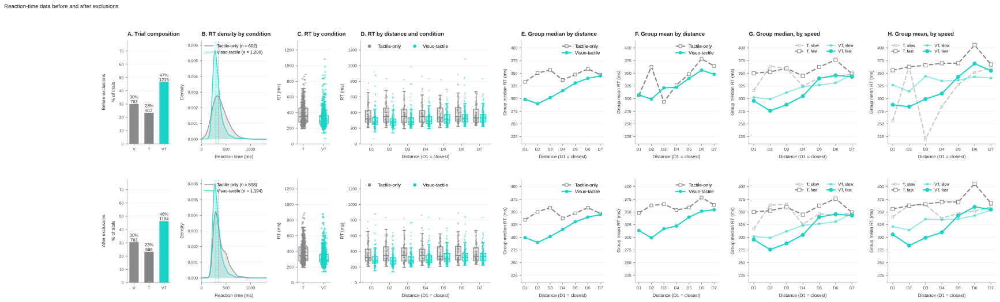

saved /Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/results/young_controls/data_exclusions/inspection_young_median_without_classic.png


PosixPath('/Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/results/young_controls/data_exclusions/inspection_young_median_without_classic.png')

In [7]:
fig = qc.plot_inspection(young.marked, statistic="median", drop=GROUP_DROPS["qc_figures"])
plt.show()
save(fig, "inspection_young_median_without_classic")

## 2.3 PPS task: trials removed by hand

These trials were removed after looking at the data, in addition to the
preregistered rules.

Each one is listed by its `trial_index` (set in 1.1) and
marked `manual review`, so they can be counted separately or put back.

The list covers all three groups, so the patient's and the matched controls' trials are removed here too.

In [8]:
MANUAL_DROPS = {
    "patient": [4358, 4501, 4515],
    "matched": [
        # PA002
        4083, 4095, 4115, 4157, 4162, 4228, 4232, 4260, 4285,
        # T outliers
        3787, 4281,
    ],
}


def apply_manual_drops(coh, drops, reason="manual review", verbose=True):
    """Mark listed trials unusable, in place, and say what happened.

    Keyed by ``trial_index``. Duplicates and indices matching no trial are
    reported rather than passed over, because a mistyped index otherwise looks
    exactly like a trial that was already excluded.
    """
    for name, listed in drops.items():
        if name not in coh:
            continue

        cohort = coh[name]
        wanted = sorted(set(listed))
        duplicates = len(listed) - len(wanted)

        hit = cohort.marked["trial_index"].isin(wanted)
        found = set(cohort.marked.loc[hit, "trial_index"])
        unmatched = sorted(set(wanted) - found)

        marked = cohort.marked.copy()
        marked.loc[hit, "usable"] = False
        marked.loc[hit, "exclusion_reason"] = reason

        cohort.marked = marked
        cohort._trials = None          # force the analysis table to rebuild

        if verbose:
            print(f"{name:8s} removed {int(hit.sum())} of {len(wanted)} listed")
            if duplicates:
                print(f"{'':8s} {duplicates} duplicate index(es) in the list")
            if unmatched:
                print(f"{'':8s} no such trial: {unmatched}")


apply_manual_drops(coh, MANUAL_DROPS)

patient  removed 3 of 3 listed
matched  removed 11 of 11 listed


In [9]:
# Retention after rules 3 and 4 together. The manual_review column is the
# count added by the cell above.
for name, cohort in coh.items():
    print(f"\n{name}")
    print(qc.exclusion_table(cohort.marked).to_string(index=False))


young
subject  usable  no_response  interrupted  missing_rt  too_fast  too_slow  dropped_position  thin_cell  manual_review  n_tactile  n_usable  percent_kept
   P002     260            4            0           0         3         1                 0          0              0        268       260          97.0
   P003     266            2            0           0         0         0                 0          0              0        268       266          99.3
   P005     266            1            0           0         1         0                 0          0              0        268       266          99.3
   P008     218            1            0           0         0         0                 0          0              0        219       218          99.5
   P009     258            7            0           0         3         0                 0          0              0        268       258          96.3
   P010     268            0            0           0         0         0  

## 2.4 PPS task: effect of the removed trials on the VT medians

The first table counts the trials removed by hand, per participant, speed and
condition.

The second shows, for each participant with removals, the VT median at each
distance before and after exclusions. 

"Before" includes every trial with an
RT. "After" includes only usable trials, so the difference covers the
preregistered rules as well as the manual removals. 

`change_ms` is after
minus before.

In [10]:
manual = young.marked[young.marked["exclusion_reason"].eq("manual review")]

print(f"{len(manual)} trials removed by hand\n")
print(
    manual.groupby(["subject", "speed", "sensory_condition"])
    .size().unstack(fill_value=0).to_string()
)

0 trials removed by hand

Empty DataFrame
Columns: []
Index: []


In [11]:
def drop_impact(marked, subject, condition="VT"):
    """Median RT at each distance, before and after all exclusions.

    "Before" is every trial of this participant and condition that has an RT.
    "After" is the trials still usable. 
    
    The difference therefore reflects all exclusions together (preregistered rules and manual removals).

    Columns, one row per distance (D1 to D7):
        n_all, n_kept            number of trials before and after
        median_all, median_kept  median RT before and after, in ms
        change_ms                after minus before; negative means the
                                 exclusions made that cell faster
    """
    # This participant's trials in this condition that have an RT.
    one = marked[
        marked["subject"].eq(subject)
        & marked["sensory_condition"].eq(condition)
        & marked["rt_ms"].notna()
    ]

    # The same trials, keeping only those still usable.
    kept = one[one["usable"].fillna(False).astype(bool)]

    table = pd.DataFrame({
        "n_all": one.groupby("position_rank").size(),
        "n_kept": kept.groupby("position_rank").size(),
        "median_all": one.groupby("position_rank")["rt_ms"].median(),
        "median_kept": kept.groupby("position_rank")["rt_ms"].median(),
    })
    table["change_ms"] = table["median_kept"] - table["median_all"]

    return table.round(1)


# Trials removed by hand in 2.3.
manual = young.marked[young.marked["exclusion_reason"].eq("manual review")]

if manual.empty:
    print("No manual removals found. Run 2.3 first.")

# One table for each young control who had trials removed by hand.
for subject in sorted(manual["subject"].unique()):
    print(f"\n{subject}")
    print(drop_impact(young.marked, subject).to_string())

No manual removals found. Run 2.3 first.


## 2.5 PPS task: trials after the manual removals

The same figure as 2.2, drawn again now that the trials from 2.3 have been
removed. 

In 2.2 the "after" row showed the preregistered exclusions only;
here it also includes the manual removals.

 Comparing the two figures shows
what the manual removals changed.

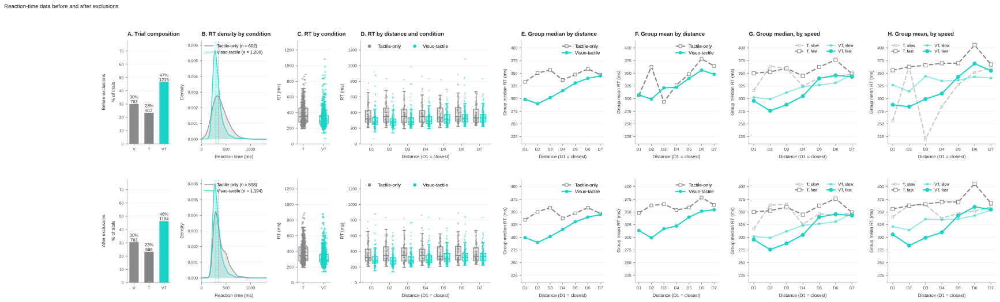

saved /Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/results/young_controls/data_exclusions/inspection_young_after_manual.png


PosixPath('/Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/results/young_controls/data_exclusions/inspection_young_after_manual.png')

In [12]:
fig = qc.plot_inspection(young.marked, statistic="median", drop=GROUP_DROPS["qc_figures"])
plt.show()
save(fig, "inspection_young_after_manual")

## 2.6 PPS task: median RT at each distance, by condition and speed

For each young control, the median RT of the usable trials at each distance,
shown separately for T and VT and for slow and fast. T001 and T002 are not
shown.

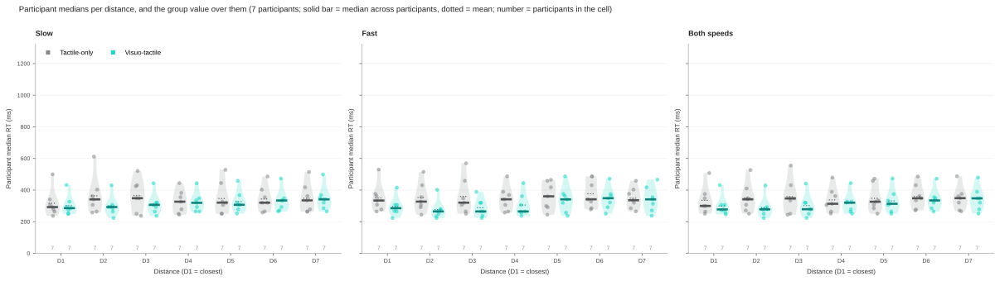

In [13]:
fig, group = qc.plot_trial_distribution(
    young.marked, stage="after", drop=GROUP_DROPS["qc_figures"],
)

fig.savefig("figures/trial_distribution_young_after.pdf",
            bbox_inches="tight")

## 2.7 PPS task: participant P005

`qc.plot_subject_deepdive` gives RT by condition, by condition and speed, by
block with early trials drawn pale, and by distance with the cell estimate
marked. Use it whenever one participant's profile looks unlike the others'.

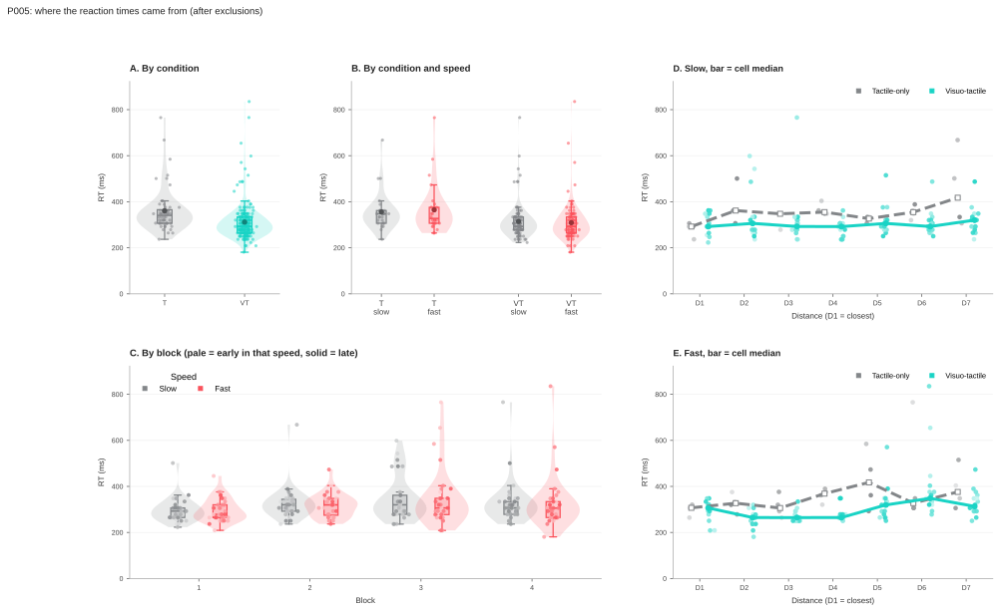

saved /Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/results/young_controls/data_exclusions/deepdive_P005.png


In [14]:
DEEPDIVE = ["P005"]

for subject in DEEPDIVE:
    fig, cells = qc.plot_subject_deepdive(young.marked, subject, stage="after")
    plt.show()
    save(fig, f"deepdive_{subject}")

## 2.8 PPS task: does facilitation change with distance?

For each participant we have one facilitation value at each of the seven
distances. Each value comes from only a few trials, so it has a standard
error: the amount it would vary if the cell were measured again with new
trials.

If a participant's seven values differ from each other by less than this
standard error, their facilitation does not measurably change with distance,
and a boundary fitted to it is not meaningful.

This is checked for every young control here, before the boundary fits
in section 4.

### Facilitation against its standard error

Each panel shows one participant's facilitation at the seven distances. The
shaded band is plus and minus one standard error of a single facilitation
value.

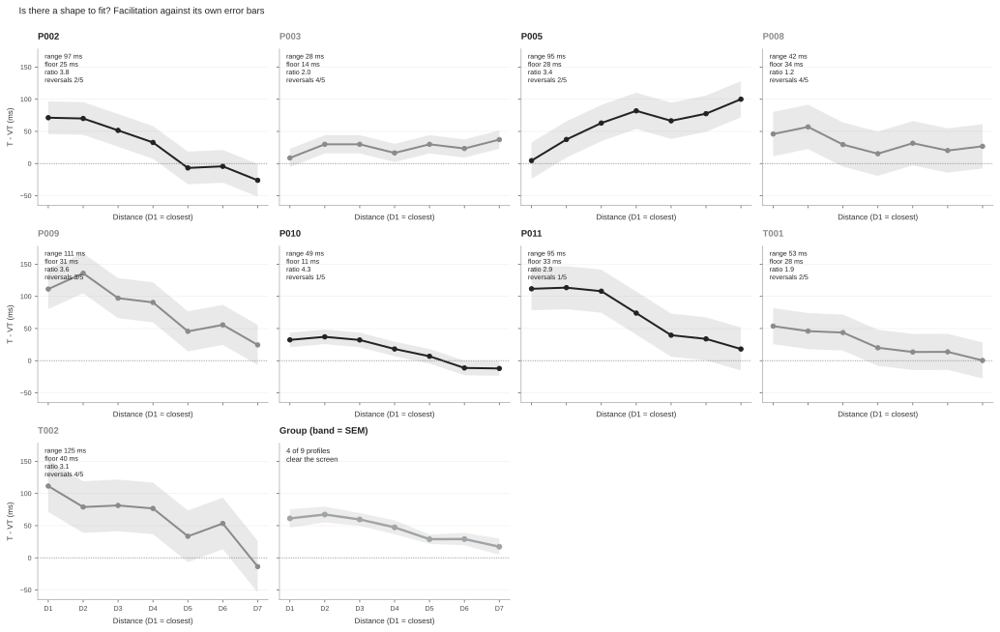

saved /Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/results/young_controls/data_exclusions/profile_legibility_young.png
subject  n_distances  range_ms  floor_ms  range_over_floor  reversals  max_reversals   rho  rho_p  mean_ms  fittable
   P002            7     97.31     25.40              3.83          2              5 -0.96   0.00    26.94      True
   P003            7     28.45     14.17              2.01          4              5  0.39   0.38    25.11     False
   P005            7     95.44     28.19              3.39          2              5  0.89   0.01    61.58      True
   P008            7     41.68     34.43              1.21          4              5 -0.64   0.12    32.35     False
   P009            7    111.37     31.14              3.58          3              5 -0.93   0.00    80.12     False
   P010            7     49.11     11.34              4.33          1              5 -0.96   0.00    14.77      True
   P011            7     95.37     

In [15]:
fig, legibility = qc.plot_profile_legibility(
    young.marked, statistic="median", baseline=CORRECTION,
)
plt.show()
save(fig, "profile_legibility_young")

print(legibility.to_string(index=False))

Two things about that panel. It collapses the speeds, so a participant with a
shape at fast and none at slow is diluted; the table below splits them. And
the band is the standard error of a per-cell tactile median regardless of the
correction, so under the expectancy model the real floor is lower than drawn
and the screen is conservative rather than optimistic.

In [16]:
for speed in ["fast", "slow"]:
    one = young.marked[young.marked["speed"].eq(speed)]

    print(f"\n=== {speed} ===")
    print(
        qc.profile_legibility(one, statistic="median", baseline=CORRECTION)
        .to_string(index=False)
    )


=== fast ===
subject  n_distances  range_ms  floor_ms  range_over_floor  reversals  max_reversals   rho  rho_p  mean_ms  fittable
   P002            7    139.28     28.21              4.94          3              5 -0.86   0.01    44.59     False
   P003            7     46.16     23.87              1.93          4              5  0.93   0.00    48.75     False
   P005            7    122.59     29.58              4.14          2              5  0.68   0.09    67.55      True
   P008            7     58.96     54.92              1.07          4              5  0.18   0.70    32.65     False
   P009            7    116.33     48.13              2.42          5              5 -0.89   0.01   104.24     False
   P010            7     66.14     16.75              3.95          2              5 -0.61   0.15    30.56      True
   P011            7    109.79     52.02              2.11          2              5 -0.71   0.07    75.74      True
   T001            7     56.37     37.38          

## 2.9 PPS task: shape of the VT profile and of the tactile baseline

`ex.vt_shape` compares flat, linear, log, quadratic and sigmoid fits to each
participant's visuo-tactile profile. `ex.tactile_shape` asks whether the
tactile-only baseline is flat, which is what the delay-matched correction
assumes. `ex.cell_precision` puts the profile range against its own noise.

In [17]:
usable_pps = young.marked.loc[young.marked["usable"]]

vt = ex.vt_shape(usable_pps)
tactile = ex.tactile_shape(usable_pps)
precision = ex.cell_precision(young.marked, n_boot=config.N_BOOT)

ex.report(vt=vt, tactile=tactile, precision=precision)


VT profile shape, per participant
      design subject  n_points  rmse_linear  rmse_log  rmse_quadratic  rmse_sigmoid      k  x_c    se_x_c  k_ok  x_c_in_range  x_c_precise                  shape preferred
intermediate    P002         7         8.21     12.39            8.02          7.80  -0.62 4.41      1.57  True          True        False                 linear    linear
intermediate    P003         7        11.10     12.35           10.80          8.22 -19.96 3.93 266387.58 False          True        False                 linear    linear
intermediate    P005         7        14.43     16.70            9.35          9.20 -40.16 4.99      0.05 False          True         True quadratic_nonmonotonic    linear
intermediate    P008         7         6.78      4.27            3.62          3.65  -0.67 2.00      1.94  True          True        False    quadratic_monotonic   sigmoid
  rebalanced    P009         7        16.04     21.01           15.66         14.01  -1.54 4.03      0.74

## 2.10 PPS task: the expectancy ramp, per participant

`h1.expectancy_baseline` is the model the hypothesis modules use to build the
`expectancy_model` baseline. It fits on `position_rank`, so `delay` is in
milliseconds per distance step outward, and `delay_x_fast` is how much steeper
the ramp is at the fast speed.

Rank 1 is the vibration that comes last in the trial, so a positive `delay`
means RT is longer when the vibration comes earlier: the temporal expectancy
pattern. A participant whose `delay` is indistinguishable from its standard
error has no ramp for the correction to remove.

In [18]:
fitted_baseline, coefficients = h1.expectancy_baseline(
    young.trials, degree=DEGREE, interaction=True,
)

print(
    coefficients[[
        "subject", "n_trials", "delay", "se_delay",
        "speed_fast", "delay_x_fast", "residual_sd_ms", "r2",
    ]].round(4).to_string(index=False)
)

subject  n_trials   delay  se_delay  speed_fast  delay_x_fast  residual_sd_ms     r2
   P002        53 -0.0639    5.5522     15.0224       -9.0352         54.9186 0.0774
   P003        56  4.1384    6.6992     29.4393        5.8527         70.8975 0.0880
   P005        56 16.0161    8.4400      9.1071        5.5687         89.3202 0.1652
   P008        60  0.7860    7.4387     19.8133       11.4325         82.8898 0.0599
   P009       120 -4.4960    6.4003     47.6476        8.9599         99.1391 0.0641
   P010       128 -5.7594    4.5237     23.4813        3.1448         73.0636 0.0407
   P011       125 -5.8668    6.4685     -6.0660        0.2986        103.3780 0.0136
   T001        68 -7.1758    5.3382      5.8412        8.1560         60.8359 0.0303
   T002        70 -2.1493    8.7561     87.4180       -4.9414        103.2218 0.1662


And the baseline those coefficients produce, per speed and distance. Compare
its range across distance against the facilitation effect: a baseline that
varies by more than the effect is doing most of the work in the subtraction.

In [19]:
print(
    fitted_baseline.pivot_table(
        index=["subject", "speed"],
        columns="position_rank",
        values="tactile_baseline_ms",
    ).round(0).to_string()
)

position_rank    1.0    2.0    3.0    4.0    5.0    6.0    7.0
subject speed                                                 
P002    fast   367.0  358.0  349.0  340.0  331.0  322.0  313.0
        slow   325.0  325.0  325.0  325.0  325.0  325.0  325.0
P003    fast   252.0  262.0  272.0  282.0  292.0  302.0  312.0
        slow   240.0  244.0  248.0  252.0  256.0  260.0  265.0
P005    fast   300.0  322.0  343.0  365.0  387.0  408.0  430.0
        slow   308.0  324.0  340.0  356.0  372.0  388.0  404.0
P008    fast   328.0  340.0  352.0  364.0  377.0  389.0  401.0
        slow   344.0  345.0  346.0  346.0  347.0  348.0  349.0
P009    fast   427.0  432.0  436.0  441.0  445.0  450.0  454.0
        slow   407.0  402.0  398.0  393.0  389.0  384.0  380.0
P010    fast   298.0  295.0  293.0  290.0  287.0  285.0  282.0
        slow   284.0  278.0  272.0  267.0  261.0  255.0  249.0
P011    fast   532.0  526.0  520.0  515.0  509.0  504.0  498.0
        slow   539.0  533.0  527.0  521.0  515.0  509.0

## 2.11 Collision task: removing reaction-time outliers

Some collision trials are already excluded when the data are loaded: those
with no valid speed, no recorded offset, no HIT or MISS answer, or an
interruption.

This step removes trials with an extreme reaction time. 

For each
participant, speed and trial type, we take the range covered by the middle
half of their RTs (the interquartile range). 

A trial is removed if its RT
lies more than 3 times that range below the lower edge or above the upper
edge.

This rule is applied to the young controls only. Each trial's
`exclusion_reason` column says whether it was kept (`usable`), excluded at
loading (`loader`), or removed here (`rt_outlier`).

In [20]:
col = young.collision

# The loader's verdict is kept in its own column, so rerunning this cell starts
# from the same trials instead of applying the outlier rule to its own output.
if "usable_loader" not in col.columns:
    col["usable_loader"] = col["usable"].fillna(False).astype(bool)

col["usable"] = col["usable_loader"]
col["exclusion_reason"] = np.where(col["usable_loader"], "usable", "loader")

print(
    f"rt_ms before the outlier rule: "
    f"{col['rt_ms'].min():.0f} to {col['rt_ms'].max():.0f} ms"
)

# Fences per participant, speed and trial type, from loader-usable trials.
keys = ["subject", "speed", "trial_type"]
kept = col["usable_loader"]
grouped = col.loc[kept].groupby(keys)["rt_ms"]

q1 = grouped.transform(lambda v: v.quantile(0.25))
q3 = grouped.transform(lambda v: v.quantile(0.75))
iqr = q3 - q1

outlier = pd.Series(False, index=col.index)
outlier.loc[kept] = (
    (col.loc[kept, "rt_ms"] < q1 - COLLISION_RT_IQR * iqr)
    | (col.loc[kept, "rt_ms"] > q3 + COLLISION_RT_IQR * iqr)
)

col.loc[outlier, "usable"] = False
col.loc[outlier, "exclusion_reason"] = "rt_outlier"

print()
print(
    young.collision.groupby("subject")["exclusion_reason"]
    .value_counts().unstack(fill_value=0).to_string()
)

removed = young.collision[~young.collision["usable"]]

if len(removed):
    print()
    print(
        removed[["subject", "speed", "trial_type", "rt_ms", "exclusion_reason"]]
        .round(0).to_string(index=False)
    )

print()
print(qc.collision_accuracy_table(young.collision)
      .round(3).to_string(index=False))

rt_ms before the outlier rule: 83 to 9526 ms

exclusion_reason  rt_outlier  usable
subject                             
P002                       5     229
P003                       3     231
P005                       1     233
P008                       2     232
P009                       3     231
P011                       0     156

subject speed trial_type  rt_ms exclusion_reason
   P002  slow  clear_hit   83.0       rt_outlier
   P002  fast  clear_hit 1016.0       rt_outlier
   P002  fast clear_miss 9231.0       rt_outlier
   P002  fast  clear_hit  946.0       rt_outlier
   P002  slow  near_miss 1615.0       rt_outlier
   P003  slow  clear_hit 1406.0       rt_outlier
   P003  fast  near_miss 7045.0       rt_outlier
   P003  slow clear_miss 1197.0       rt_outlier
   P005  slow  clear_hit 1168.0       rt_outlier
   P008  fast  near_miss 9526.0       rt_outlier
   P008  fast   near_hit 7472.0       rt_outlier
   P009  slow  near_miss 2082.0       rt_outlier
   P009  slow clear_

## 2.12 Collision task: trials before and after the outlier rule

The figure has four rows: before and after exclusions, each split into slow
and fast. Each row shows:

- how many trials of each type there are;
- the RT distributions of near-hit and near-miss trials;
- RT by trial type, with every trial drawn;
- RT by participant and trial type.

The before and after rows share their axes, so the difference between them
is what the exclusions removed.

  saved: figures/h3_inspection_young.svg
  saved: figures/h3_inspection_young.pdf


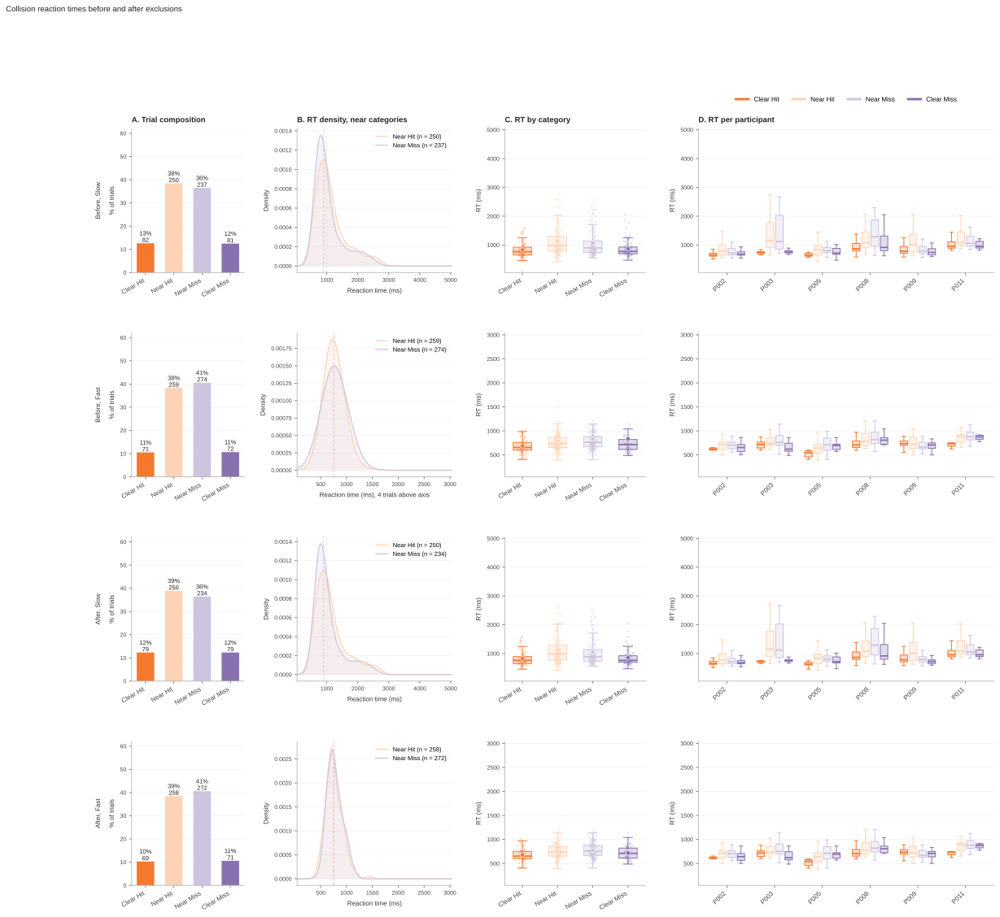

In [21]:
h3.collision_inspection(
    young.collision,
    save_as="h3_inspection_young",
);

## 2.13 Collision task: accuracy and reaction time

The table summarises accuracy and reaction time for each participant. 

The figures that follow show reaction time by trial type and speed, accuracy by
clearance, and each participant's responses across clearance.

Clear trials check that participants understood the task: accuracy there
should be near ceiling. Near trials are the hard judgements, so a speed
effect is most likely to show there.

Collision performance per participant and speed

subject speed  n_trials  accuracy  hit_rate  false_alarm_rate  near_accuracy  n_near  rt_min  rt_median  rt_max  rt_iqr
   P002  fast       114     0.851     0.862             0.161          0.903      31  500.76    681.735 1086.05 149.548
   P002  slow       115     0.826     0.804             0.153          0.786      28  515.17    723.720 1921.57 216.225
   P003  fast       114     0.868     0.925             0.180          0.913      23  487.49    738.105 1141.56 205.140
   P003  slow       117     0.949     0.952             0.056          1.000      36  654.23    974.550 2742.32 765.590
   P005  fast       122     0.787     0.892             0.333          0.900      30  389.71    654.765 1197.21 204.870
   P005  slow       111     0.865     0.764             0.036          0.781      32  417.64    765.450 1447.76 264.480
   P008  fast       122     0.779     0.867             0.306          0.848      33  569.21    791.705 1499.21

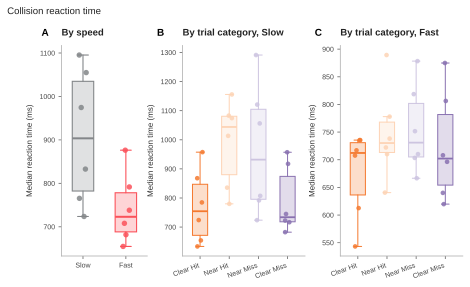

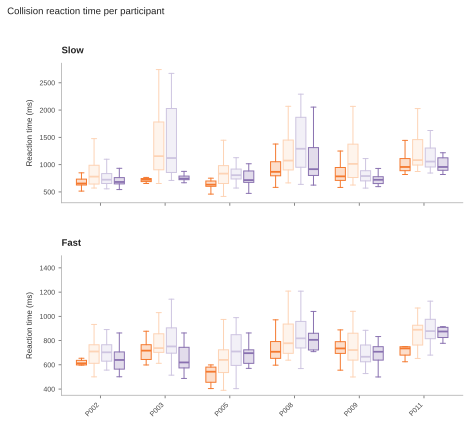

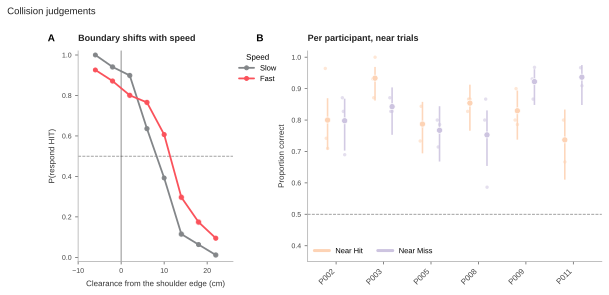

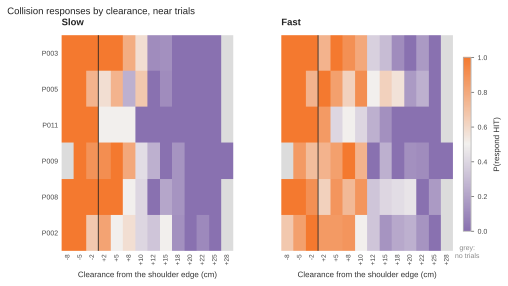

In [22]:
# Table, one row per participant: accuracy, hits (saying HIT when the ball
# would have hit), false alarms (saying HIT when it would have missed), and
# reaction time. Hits and false alarms are shown separately because someone
# who says HIT to everything can still score a fair accuracy.
descriptives = h3.collision_descriptives(young.collision)

# Two figures of reaction time.
# First: (A) slow against fast, (B) RT by trial type within slow trials,
# (C) the same within fast trials. Near trials are the hard judgements and
# are expected to take longer.
# Second: the same split for each participant, one row per speed.
h3.plot_collision_rt(
    young.collision, show_legend=False, save_as="h3_rt_young",
);

# Accuracy, two panels.
# (A) Proportion correct by clearance (the gap between ball and body),
# averaged over participants. Accuracy should rise as the ball passes
# further from the boundary.
# (B) Each participant's accuracy on near-hit and near-miss trials, with a
# 95% interval. Small points behind each marker are the separate blocks.
h3.plot_collision_accuracy(
    young.collision,
    ball_radius_cm=BALL_RADIUS_CM,
    save_as="h3_accuracy_young",
);

# Each participant's answers by clearance, one row per participant, split by
# speed. Orange means they answered HIT, purple MISS. A clean change from
# orange to purple near zero means a clear boundary; a patchy row means no
# boundary can be fitted for that participant.
h3.plot_collision_response_map(
    young.collision,
    ball_radius_cm=BALL_RADIUS_CM,
    save_as="h3_response_map_young",
);

# 3. Patient and matched controls: quality control and descriptives

The same checks for the patient (PT001) and the two matched controls (PA001
and PA002): first the PPS task, then the collision task. The patient is
compared with PA002 in section 5.

The collision outlier rule in 2.11 was applied to the young controls only,
so these collision trials have the loading rules alone.

In [23]:
# The patient and PA002 together, for the figures below and for
# sections 5 and 6. Built here, after the manual removals in 2.3.
clin = pa.tables.clinical(data, coh, control_id=MATCHED_CONTROL)
print(clin)

<Clinical: patient=PT001, control=PA002, session=None, 2989 PPS trials>


## 3.1 PPS task: exclusions

The table shows, for the patient, PA001 and PA002, how many PPS trials were
excluded and why, and the percentage each person kept (`percent_kept`).

In [24]:
for name in CLINICAL:
    print("\n" + "=" * 70)
    print(f"{name}: {coh[name].subject_ids}")
    print("=" * 70)
    print(qc.exclusion_table(coh[name].marked).to_string(index=False))


matched: ['PA001', 'PA002']
subject  usable  no_response  interrupted  missing_rt  too_fast  too_slow  dropped_position  thin_cell  manual_review  n_tactile  n_usable  percent_kept
  PA001     213            5            0           0         0         0                 0          0              0        218       213          97.7
  PA002     189            1            0           0         0         1                 0          0              0        191       189          99.0

patient: ['PT001']
subject  usable  no_response  interrupted  missing_rt  too_fast  too_slow  dropped_position  thin_cell  manual_review  n_tactile  n_usable  percent_kept
  PT001     195            0            0           0         2         1                 0          0              0        198       195          98.5


## 3.2 PPS task: trials before and after exclusions

One figure per group, in the same layout as 2.2: first the matched controls,
then the patient.


matched: PA001, PA002


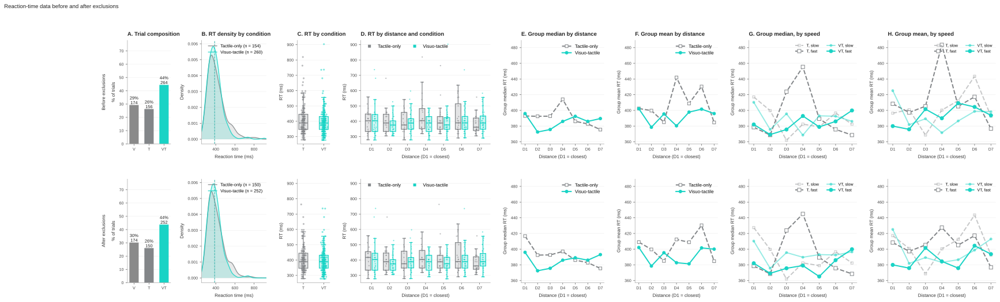

saved /Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/results/young_controls/data_exclusions/inspection_matched_median.png

patient: PT001


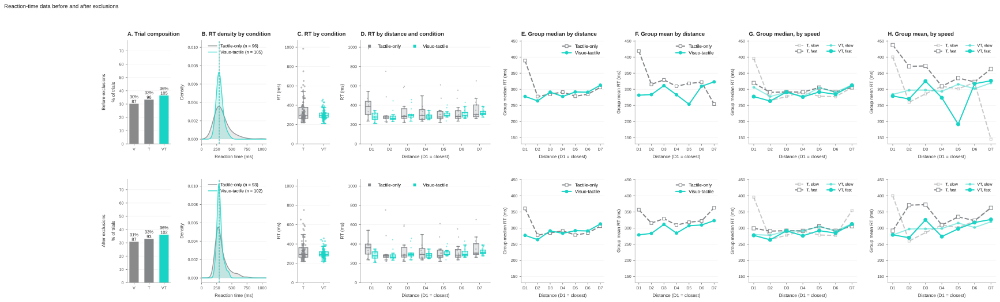

saved /Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/results/young_controls/data_exclusions/inspection_patient_median.png


In [25]:
# One figure per clinical group (matched controls, then the patient): the
# PPS trials before and after exclusions, in the same layout as 2.2.
for name in CLINICAL:
    print(f"\n{name}: {', '.join(coh[name].subject_ids)}")

    fig = qc.plot_inspection(coh[name].marked, statistic="median")
    plt.show()
    save(fig, f"inspection_{name}_median")

## 3.3 PPS task: facilitation profile fits for the patient and PA002

The H1a model fits (section 4) applied to each of them on their own.

PT001
Trials entering H1: 195 of 195 (0 excluded by QC)
  saved: figures/h1a_sigmoid_shape.svg
  saved: figures/h1a_sigmoid_shape.pdf


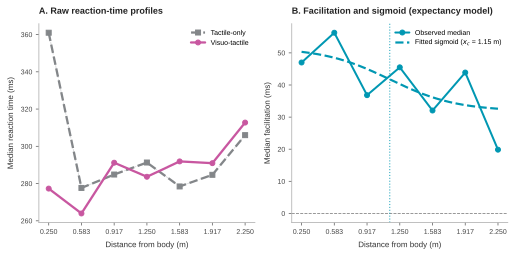

  saved: figures/h1a_individual_fits.svg
  saved: figures/h1a_individual_fits.pdf


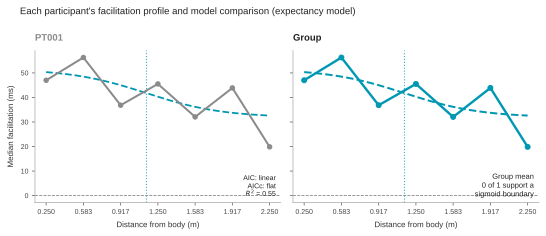

subject  aic_flat  aic_linear  aic_sigmoid  aic_delta_vs_flat  aic_delta_vs_linear  aicc_flat  aicc_linear  aicc_sigmoid  aicc_delta_vs_flat  aicc_delta_vs_linear  rss_flat  rss_linear  rss_sigmoid  r2_sigmoid   x_c  se_x_c     k  se_k  amplitude_ms  sigmoid_ok  x_c_in_range  x_c_precise  k_ok  k_at_bound  transition_width_10_90  transition_direction_ok  transition_width_ok  bootstrap_n  bootstrap_n_valid  bootstrap_success_rate  bootstrap_x_c_median  bootstrap_x_c_ci_low  bootstrap_x_c_ci_high  bootstrap_x_c_ci_width  bootstrap_precise  boundary_estimable  halfmax_rank  halfmax_m boundary_method  boundary_rank  boundary_m preferred preferred_aicc    low   high  sigmoid_lower_aic  sigmoid_boundary_estimable
  PT001    57.362      54.148       57.797              0.434                3.649     60.362       62.148       117.797              57.434                55.649   838.157     397.943      378.467       0.548 3.694   1.188 0.981 1.041        19.775        True          True        

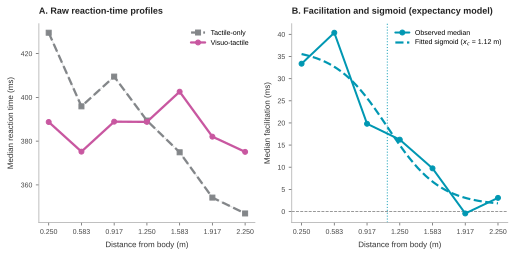

  saved: figures/h1a_individual_fits.svg
  saved: figures/h1a_individual_fits.pdf


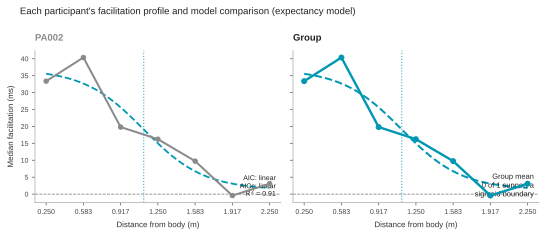

subject  aic_flat  aic_linear  aic_sigmoid  aic_delta_vs_flat  aic_delta_vs_linear  aicc_flat  aicc_linear  aicc_sigmoid  aicc_delta_vs_flat  aicc_delta_vs_linear  rss_flat  rss_linear  rss_sigmoid  r2_sigmoid  x_c  se_x_c     k  se_k  amplitude_ms  sigmoid_ok  x_c_in_range  x_c_precise  k_ok  k_at_bound  transition_width_10_90  transition_direction_ok  transition_width_ok  bootstrap_n  bootstrap_n_valid  bootstrap_success_rate  bootstrap_x_c_median  bootstrap_x_c_ci_low  bootstrap_x_c_ci_high  bootstrap_x_c_ci_width  bootstrap_precise  boundary_estimable  halfmax_rank  halfmax_m boundary_method  boundary_rank  boundary_m preferred preferred_aicc   low  high  sigmoid_lower_aic  sigmoid_boundary_estimable
  PA002    60.809      48.649       49.705            -11.104                1.056     63.809       56.649       109.705              45.896                53.056  1371.476     181.417      119.127       0.913 3.62   0.306 1.242 0.419        35.547        True          True         Tru

In [26]:
def one_subject(cohort, subject):
    """A cohort copy holding one participant, original untouched."""
    clone = copy.copy(cohort)
    clone.marked = cohort.marked[cohort.marked["subject"] == subject].copy()
    clone._trials = None
    clone.name = subject
    return clone


for subject, source in [(PATIENT, patient),
                        (MATCHED_CONTROL, matched)]:
    print("=" * 60)
    print(subject)

    r = h1a.run(
        one_subject(source, subject),
        estimator="median", correction=CORRECTION,
        min_cell_n=H1A_MIN_CELL_N, n_boot=H1A_N_BOOT, plot=True,
        verbose=False,
    )

    r["figure"].savefig(
        f"figures/h1a_sigmoid_{subject}.pdf", bbox_inches="tight",
    )

    print(r["table"].round(3).to_string(index=False))

## 3.4 Collision task: psychometric curves, accuracy and reaction time

The patient and PA002 side by side: the proportion of HIT answers by
clearance at each speed, then accuracy and reaction time.

  saved: figures/h6_psychometric_by_speed.svg
  saved: figures/h6_psychometric_by_speed.pdf


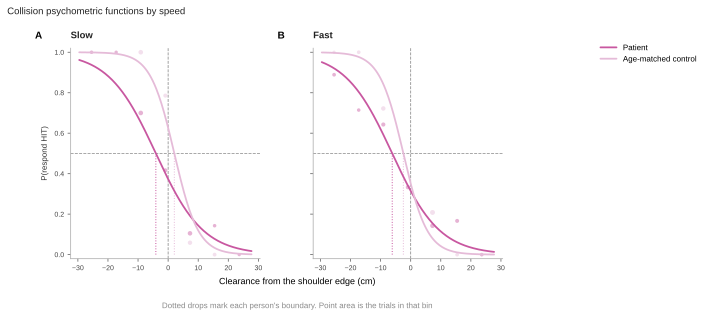

In [27]:
h3.plot_clinical_psychometric_by_speed(
    clin.collision_trials,
    patient=PATIENT,
    controls=[MATCHED_CONTROL],
    ball_radius_cm=BALL_RADIUS_CM,
    save_as="h6_psychometric_by_speed",
);

  saved: figures/h6_clinical_accuracy.svg
  saved: figures/h6_clinical_accuracy.pdf
  saved: figures/h6_clinical_rt.svg
  saved: figures/h6_clinical_rt.pdf


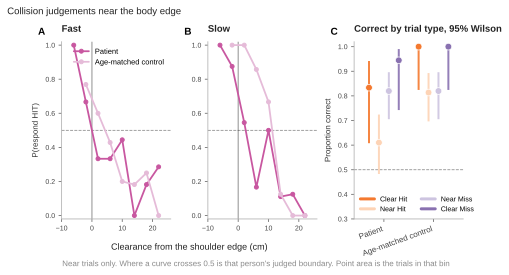

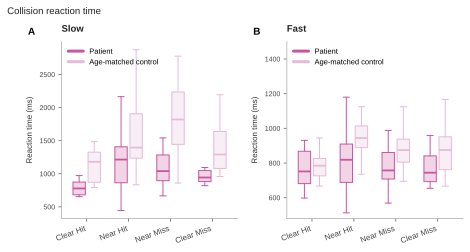

In [28]:
h3.plot_clinical_accuracy(
    clin.collision_trials,
    patient=PATIENT,
    controls=[MATCHED_CONTROL],
    ball_radius_cm=BALL_RADIUS_CM,
    save_as="h6_clinical_accuracy",
);

h3.plot_clinical_rt(
    clin.collision_trials,
    patient=PATIENT,
    controls=[MATCHED_CONTROL],
    save_as="h6_clinical_rt",
);

# 4. Aim 1: Peripersonal space in healthy adults

## H1. Facilitation is stronger near the body

`h1.facilitation_profile` returns one profile per participant and speed;
`h1.nearfar_table` reduces it to near minus far; `h1.group_test` runs the
bootstrap interval and the one-sided Wilcoxon test.

Participants: the young cohort minus `GROUP_DROPS["h1_group_test"]`, which is
empty, so the classic design is included here and excluded in H1.4 and H1.5.

In [29]:
trials_h1 = young.trials.loc[~young.trials["subject"].isin(GROUP_DROPS["h1_group_test"])]

profile = h1.facilitation_profile(
    trials_h1,
    estimator="median",
    correction=CORRECTION,
    expectancy_degree=DEGREE,
)

print(
    profile.pivot_table(
        index=["subject", "speed"],
        columns="position_rank",
        values="facilitation_ms",
    ).round(0).to_string()
)

position_rank    1.0    2.0    3.0    4.0   5.0   6.0    7.0
subject speed                                               
P002    fast   103.0  108.0   85.0   75.0 -32.0   1.0  -28.0
        slow    39.0   32.0   18.0  -10.0  18.0  -9.0  -24.0
P003    fast    28.0   39.0   49.0   45.0  55.0  51.0   74.0
        slow   -11.0   21.0   11.0  -12.0   5.0  -4.0   -0.0
P005    fast    -6.0   57.0   79.0  100.0  67.0  60.0  116.0
        slow    15.0   18.0   47.0   64.0  66.0  95.0   84.0
P008    fast    21.0   62.0   33.0    3.0  36.0  27.0   46.0
        slow    70.0   52.0   26.0   27.0  28.0  14.0    8.0
P009    fast   142.0  154.0  117.0  135.0  70.0  74.0   37.0
        slow    81.0  118.0   78.0   46.0  21.0  37.0   12.0
P010    fast    30.0   60.0   56.0   33.0  31.0  -7.0   11.0
        slow    35.0   14.0    9.0    3.0 -17.0 -16.0  -35.0
P011    fast   117.0  124.0  132.0   70.0  23.0  32.0   32.0
        slow   106.0  102.0   84.0   78.0  57.0  36.0    5.0
T001    fast    61.0   6

### H1.1 The group profile

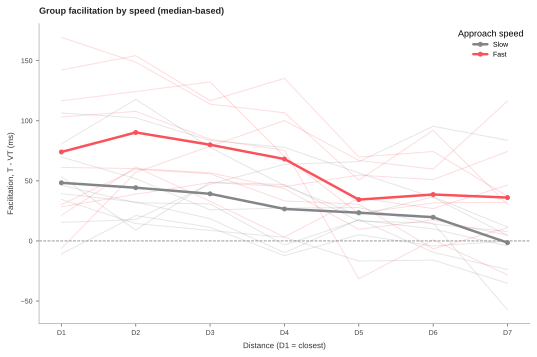

saved /Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/results/young_controls/data_exclusions/h1_group_facilitation_by_speed.png
speed  position_rank  group_mean  group_sd  n  group_sem
 fast            1.0        74.0      61.0  9       20.3
 fast            2.0        90.3      43.8  9       14.6
 fast            3.0        80.0      34.6  9       11.5
 fast            4.0        68.1      41.3  9       13.8
 fast            5.0        34.4      31.8  9       10.6
 fast            6.0        38.6      33.2  9       11.1
 fast            7.0        36.1      41.6  9       13.9
 slow            1.0        48.4      35.0  9       11.7
 slow            2.0        44.3      39.5  9       13.2
 slow            3.0        39.2      27.4  9        9.1
 slow            4.0        26.6      33.7  9       11.2
 slow            5.0        23.5      25.0  9        8.3
 slow            6.0        19.7      33.8  9       11.3
 slow            7.0        -1.4      39.2  9     

In [30]:
fig, individual, group = h1.plot_group_facilitation(
    profile, estimator="median", by_speed=True, show_individuals=True,
)
plt.show()
save(fig, "h1_group_facilitation_by_speed")

print(group.round(1).to_string(index=False))

### H1.2 Near minus far, per participant and as a group

In [31]:
nearfar = h1.nearfar_by_subject(profile, by_speed=True, design_map=DESIGN)
print(nearfar.round(1).to_string(index=False))

subject speed  near_facilitation  far_facilitation  nearfar_pps  n_near  n_far       design
   P002  fast              105.5             -13.7        119.2       2      2 intermediate
   P002  slow               35.9             -16.7         52.5       2      2 intermediate
   P003  fast               33.6              62.7        -29.1       2      2 intermediate
   P003  slow                5.2              -2.2          7.3       2      2 intermediate
   P005  fast               25.4              88.1        -62.6       2      2 intermediate
   P005  slow               16.6              89.5        -72.9       2      2 intermediate
   P008  fast               41.4              36.7          4.7       2      2 intermediate
   P008  slow               60.8              10.9         49.9       2      2 intermediate
   P009  fast              148.2              55.8         92.4       2      2   rebalanced
   P009  slow               99.3              24.1         75.2       2      2  

In [32]:
nearfar_collapsed = h1.nearfar_table(profile)
result_h1 = h1.group_test(nearfar_collapsed)

print(pd.Series(result_h1).to_string())

n                     9
mean          40.974961
ci_low         6.363626
ci_high       69.240356
wilcoxon_W         39.0
wilcoxon_p     0.027344
supported          True


### H1.3 Profiles by trial-composition design

The three designs differ in how often a vibration follows the looming
stimulus. If the correction has absorbed that, the spread within each design
should be wider than the differences between them.

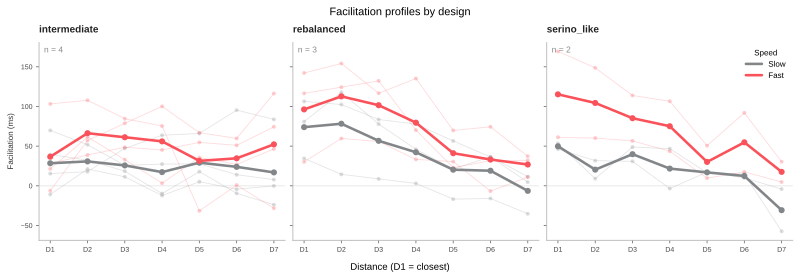

In [33]:
h1.plot_facilitation_by_design(
    profile, DESIGN, save_path="figures/facilitationbydesign.pdf"
);

### H1.4 Facilitation under each baseline correction

`bc.compare` builds every correction's profile on the same participants and
separates level, shape and the near-far result. Participants: the young
cohort minus `GROUP_DROPS["baseline_comparison"]`.

Excluded: T001, T002
Baseline corrections compared
7 participants, median cell estimator, expectancy degree 1
  P002, P003, P005, P008, P009, P010, P011
  excluded: T001, T002

1. Level: the group profile under each correction

correction           delay_matched  expectancy_model  fastest_tactile  noel_endpoints  overall_tactile
speed position_rank                                                                                   
fast  1.0                     54.6              62.2             24.5            38.3             60.9
      2.0                     76.8              86.2             44.0            57.9             80.4
      3.0                     71.5              78.5             31.9            45.8             68.3
      4.0                     39.9              66.1             15.1            29.0             51.5
      5.0                     22.4              35.6            -19.9            -6.0             16.6
      6.0                     30.5              34.

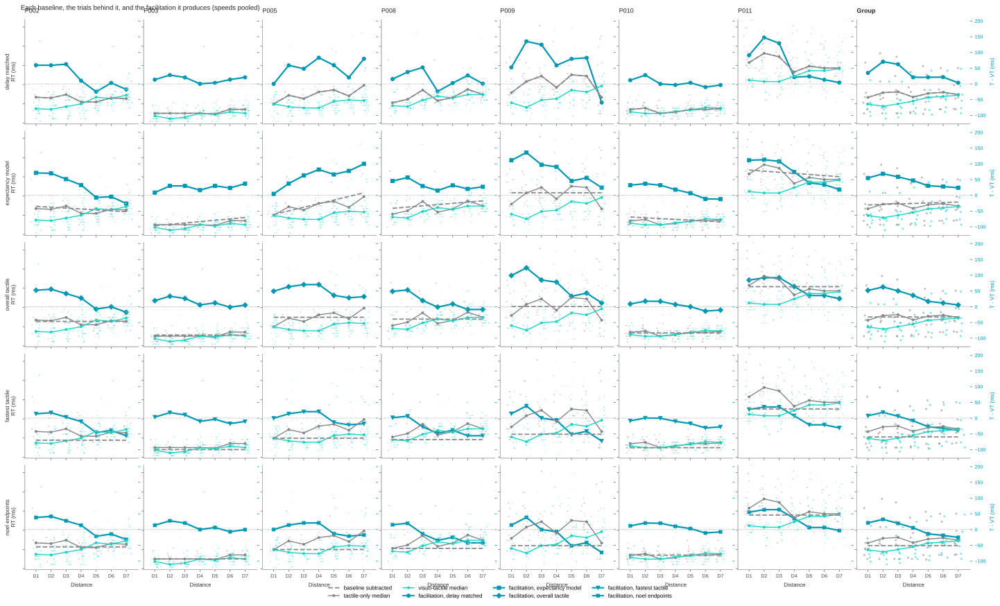

In [34]:
bc_result = bc.compare(
    young.trials, degree=DEGREE, exclude=GROUP_DROPS["baseline_comparison"],
)
bc.report(bc_result)

fig = bc.plot_correction_by_subject(
    bc_result, young.trials, save_as="baseline_by_subject",
)

  saved: figures/expectancy_group_correction.svg
  saved: figures/expectancy_group_correction.pdf


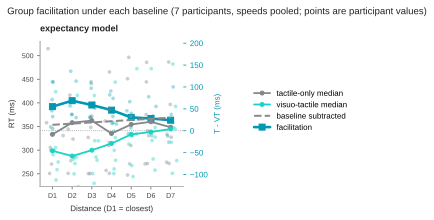

In [35]:
fig = bc.plot_group_corrections(
    bc_result, corrections=[CORRECTION],
    save_as="expectancy_group_correction",
)

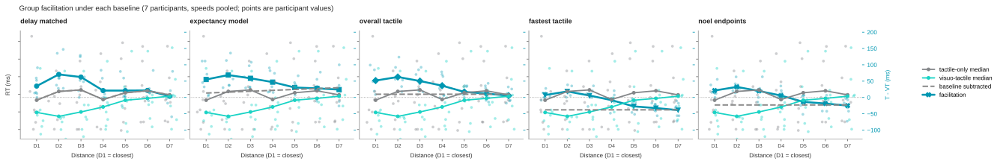

In [36]:
fig = bc.plot_group_corrections(bc_result)

### H1.5 Trial-level intervals

`bf.run` resamples trials within cells, rebuilds each participant's profile on
every draw, and returns a percentile interval per participant plus the group
test on both indices. `failed` counts draws where a resample left a cell
empty; a count above a few percent means the estimate is fragile in a way the
interval alone does not convey.

Participants: the young cohort minus `GROUP_DROPS["h1_trial_bootstrap"]`.

In [37]:
boot_h1 = bf.run(
    young.trials,
    exclude=GROUP_DROPS["h1_trial_bootstrap"],
    correction=CORRECTION,
    expectancy_degree=DEGREE,
)

print(boot_h1["group_nearfar"])

Excluded: T001, T002

5000 draws, resampled within session, speed, position_rank, sensory_condition

               overall_ms  overall_ms_low  overall_ms_high  overall_ms_above_zero  nearfar_ms  nearfar_ms_low  nearfar_ms_high  nearfar_ms_above_zero  failed
subject speed                                                                                                                                                
P002    fast       44.589          24.211           65.074                  1.000     119.171          61.897          169.892                  1.000       0
        slow        9.283         -17.042           33.655                  0.721      52.545         -24.392          126.532                  0.894       0
P003    fast       48.750          21.217           81.951                  1.000     -29.130        -119.038           30.024                  0.239       0
        slow        1.475          -9.965           10.364                  0.518       7.308         -16.576

Excluded: T001, T002
subject  near_facilitation  far_facilitation  nearfar_pps
   P002               70.7             -15.2         85.9
   P003               19.4              30.3        -10.9
   P005               21.0              88.8        -67.8
   P008               51.1              23.8         27.3
   P009              123.7              40.0         83.8
   P010               34.7             -11.7         46.4
   P011              112.4              26.2         86.2

  n                = 7
  mean near-far    = 35.8 ms
  bootstrap 95% CI = [-7.8, 71.7]
  Wilcoxon         = W 23.0, p 0.0781 (ns)
{'n': 7, 'mean': 35.83721433167026, 'ci_low': -7.817118322588644, 'ci_high': 71.66162280996873, 'W': 23.0, 'p': 0.078125}


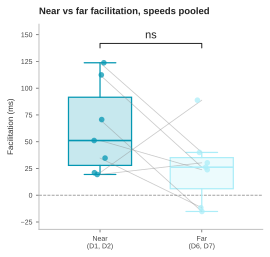

In [38]:
prof = h1.facilitation_profile(
    young.trials, estimator="median",
    correction=CORRECTION, expectancy_degree=DEGREE,
)

fig, table, stats_boxes = h1.plot_nearfar_boxes(
    prof, exclude=GROUP_DROPS["h1_nearfar_boxes"],
    save_path=f"figures/h1_nearfar_boxes_{CORRECTION}.pdf",
)

print(stats_boxes)

## H1a. The profile is sigmoidal

`h1a.run` fits flat, linear, log, quadratic and sigmoid models per participant
and reports which is preferred, whether the midpoint is estimable, and why not
where it is not.

Participants: the young cohort minus `GROUP_DROPS["h1a"]`. Trials: rules 3 and
4, then rule 4b (cells below `H1A_MIN_CELL_N` trials give no estimate).

Trials entering H1: 2392 of 2392 (0 excluded by QC)
  saved: figures/h1a_sigmoid_shape.svg
  saved: figures/h1a_sigmoid_shape.pdf


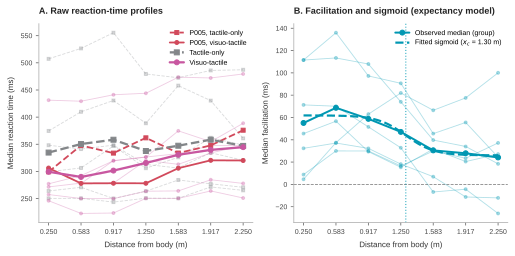

  saved: figures/h1a_individual_fits.svg
  saved: figures/h1a_individual_fits.pdf


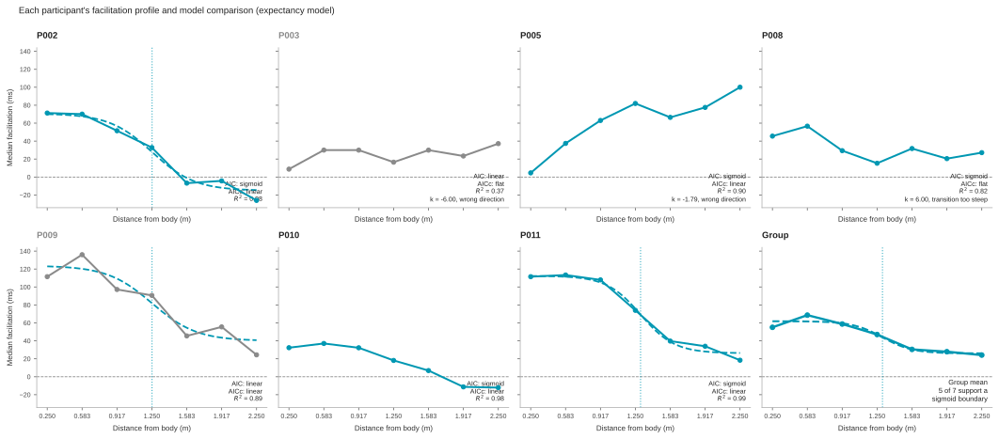

{'n_trials_in': 1792, 'used_usable_column': True, 'n_trials_excluded': 0, 'n_cells_before': 196, 'n_cells_thin': 0, 'n_trials_in_thin_cells': 0, 'n_trials_used': 1792, 'n_cells_used': 196, 'min_cell_n': 3, 'n_profile_points_dropped': 0, 'points_per_subject':   subject  n_distances
0    P002            7
1    P003            7
2    P005            7
3    P008            7
4    P009            7
5    P010            7
6    P011            7}

subject  aic_flat  aic_linear  aic_sigmoid  aic_delta_vs_flat  aic_delta_vs_linear  aicc_flat  aicc_linear  aicc_sigmoid  aicc_delta_vs_flat  aicc_delta_vs_linear  rss_flat  rss_linear  rss_sigmoid  r2_sigmoid   x_c  se_x_c      k    se_k  amplitude_ms  sigmoid_ok  x_c_in_range  x_c_precise  k_ok  k_at_bound  transition_width_10_90  transition_direction_ok  transition_width_ok  bootstrap_n  bootstrap_n_valid  bootstrap_success_rate  bootstrap_x_c_median  bootstrap_x_c_ci_low  bootstrap_x_c_ci_high  bootstrap_x_c_ci_width  bootstrap_precise  boundary

In [39]:
h1a.HIGHLIGHT_SUBJECT = "P005"

r_h1a = h1a.run(
    young, estimator="median", correction=CORRECTION,
    exclude=GROUP_DROPS["h1a"],
    min_cell_n=H1A_MIN_CELL_N, n_boot=H1A_N_BOOT, plot=True, verbose=False,
)

r_h1a["figure"].savefig(
    f"figures/h1a_sigmoid_shape_{CORRECTION}.pdf", bbox_inches="tight",
)

# What rule 4b removed
accounting = r_h1a.get("trial_accounting", {})
print({k: v for k, v in accounting.items() if k != "thin_cells"})
print()

# The per-participant sigmoid parameters
print(r_h1a["table"].round(3).to_string(index=False))

# The group fit
print("\ngroup x_c (m):", r_h1a["group_x_c_m"])
print("usable:", r_h1a["group_boundary_usable"])
print(r_h1a["group_summary"].round(3).to_string(index=False))

### H1a.1 Individual fits

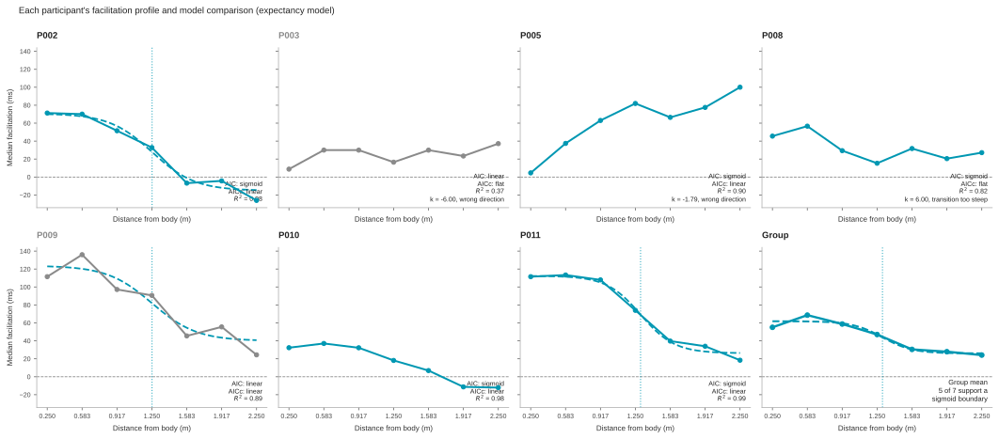

In [40]:
h1a.plot_individual_fits(r_h1a);

### H1a.2 The half-maximum fallback

Where the fitted centre is not estimable, the preregistration reads the
boundary off the observed profile instead: far plateau from D6 and D7, near
plateau from D1 and D2, half maximum midway, first inward crossing
interpolated.

In [41]:
halfmax = h1.half_max_boundary(profile)
print(halfmax.round(2).to_string(index=False))

print()
print(h1.delta_pps(halfmax).round(3).to_string(index=False))

subject speed  far_plateau  near_plateau  half_level  x_half_rank  x_half_m  bracket_outer  bracket_inner  halfmax_ok reason
   P002  fast       -13.68        105.49       45.91         4.28      1.34              5              4        True     ok
   P002  slow       -16.68         35.87        9.60         5.30      1.68              6              5        True     ok
   P003  fast        62.75         33.62       48.18         4.31      1.35              5              4        True     ok
   P003  slow        -2.15          5.16        1.50         5.39      1.71              6              5        True     ok
   P005  fast        88.07         25.44       56.75         1.99      0.58              2              1        True     ok
   P005  slow        89.54         16.61       53.07         3.35      1.03              4              3        True     ok
   P008  fast        36.72         41.43       39.08         6.62      2.12              7              6        True     ok


## H2. The boundary moves outward for faster approach

`h2.run_by_speed` fits the boundary separately by speed and returns
`speed_fits` (one row per participant and speed) and `boundaries` (fast minus
slow). `boundaries` is what H7a reads, so it is kept under its own name.

Participants: the young cohort minus `GROUP_DROPS["h2"]`. The figure also
leaves out the participants in `GROUP_DROPS["h2_figure"]`, so where the two
lists differ the figure and the test describe different samples.

In [42]:
trials_h2 = young.trials.loc[~young.trials["subject"].isin(GROUP_DROPS["h2"])]

print(
    f"{trials_h2['subject'].nunique()} of "
    f"{young.trials['subject'].nunique()} participants: "
    f"{', '.join(sorted(trials_h2['subject'].unique()))}"
)

r_h2 = h2.run_by_speed(
    trials_h2,
    corrections=(CORRECTION,),
    estimator="median",
    expectancy_degree=DEGREE,
)

boundaries = r_h2["boundaries"]

7 of 9 participants: P002, P003, P005, P008, P009, P010, P011
Boundaries per participant and speed
  fitted with the H1a boundary sigmoid: plateaus fixed from the data, midpoint and slope estimated

  expectancy_model   11 of 14 fits sound,  5 participant(s) with both speeds

expectancy_model
  n                = 5
  mean Delta_PPS   = +0.250 ranks
  bootstrap 95% CI = [-0.387, +0.887]
  Wilcoxon         = W 10.0, p 0.3125



In [43]:
print(
    r_h2["speed_fits"]
    .loc[r_h2["speed_fits"]["fit_ok"], ["subject", "speed", "x_c", "se_x_c", "k"]]
    .round(3).to_string(index=False)
)

subject speed   x_c  se_x_c     k
   P002  fast 4.175   0.551 6.000
   P002  slow 3.869   0.670 0.899
   P003  slow 3.460   4.367 6.000
   P008  fast 2.642  13.840 6.000
   P008  slow 3.160   0.462 1.072
   P009  fast 4.451   0.366 1.731
   P009  slow 3.541   0.327 2.407
   P010  fast 5.108   1.147 6.000
   P010  slow 3.952   0.380 1.168
   P011  fast 3.955   0.172 6.000
   P011  slow 4.559   0.278 1.206


Excluded: P005
  not present: T001, T002
speed   x_c  se_x_c     k  k_at_bound
 slow 3.858   0.274 1.159       False
 fast 4.093   0.135 3.439       False


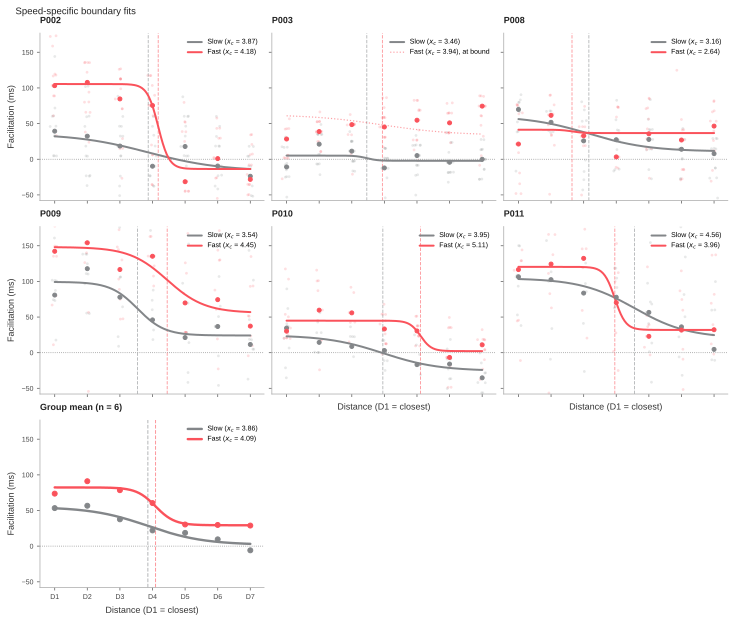

In [44]:
fig, group_fits = h2.plot_speed_fits(
    trials_h2, r_h2["speed_fits"],
    correction=CORRECTION, expectancy_degree=DEGREE,
    exclude=GROUP_DROPS["h2_figure"],
    show_trials=True,
)

fig.savefig(
    "/Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/"
    "figures/h2_speed_fits_young.pdf",
    bbox_inches="tight",
)

print(group_fits.round(3).to_string(index=False))

## H3. The collision boundary shifts with ball speed

`h3.run` fits the psychometric function per speed, takes the PSE difference,
and tests it across participants. With `ball_radius_cm` set, offsets are
converted to clearance (0.4) before fitting, so the PSEs are gaps between the
ball's surface and the shoulder edge. `Delta_coll` is a difference and does not
depend on the conversion.

Participants: young controls with collision trials, minus `GROUP_DROPS["h3"]`.
Trials: rules 5 and 6.

H3 on 6 young controls: P002, P003, P005, P008, P009, P011

H3, step 1: Delta_coll per participant
  Delta_coll = PSE(fast) - PSE(slow), in cm.
  Positive = the collision boundary moved outward for a fast ball.

subject  delta_coll
   P002        1.33
   P003        1.51
   P005        8.78
   P008        3.50
   P009       -1.23
   P011        2.10

H3, step 2: group test
  number of participants  = 6
  mean Delta_coll         = 2.66 cm
  bootstrap 95% CI        = [0.54, 5.44] cm
  Wilcoxon (one-sided)    = W 20.0, p 0.0312

  H3 IS SUPPORTED: mean > 0 and the 95% CI lies above zero.
  saved: figures/h3_delta_coll.svg
  saved: figures/h3_delta_coll.pdf


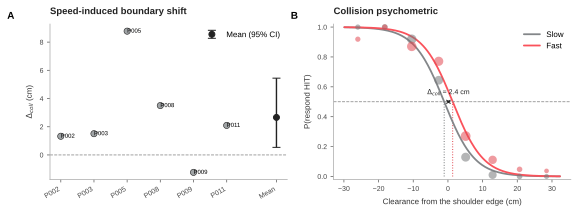

In [45]:
r_h3 = h3.run(
    young,
    exclude=GROUP_DROPS["h3"],
    ball_radius_cm=BALL_RADIUS_CM,
    save_as="h3_delta_coll",
)

In [46]:
print(r_h3["collision_indices_young"].round(3).to_string(index=False))

subject  pse_slow  pse_fast  delta_coll     b0  b_offset  b_speed  n_trials  fit_ok
   P002    -0.854     0.472       1.326 -0.036    -0.191    0.126       229    True
   P003     0.114     1.621       1.508  0.286    -0.330    0.249       231    True
   P005    -3.910     4.868       8.778  0.107    -0.224    0.984       233    True
   P008     0.387     3.889       3.502  0.460    -0.215    0.376       232    True
   P009     0.776    -0.459      -1.235  0.035    -0.220   -0.136       231    True
   P011    -5.159    -3.063       2.096 -1.616    -0.393    0.412       156    True


  saved: figures/h3_response_map_young.svg
  saved: figures/h3_response_map_young.pdf


(<Figure size 864x468 with 3 Axes>,
 subject
 P003    1.00
 P005    1.00
 P011    1.00
 P009    0.92
 P008    0.89
 P002    0.86
 dtype: float64)

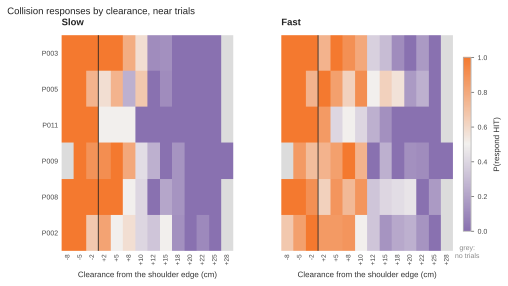

In [47]:
h3.plot_collision_response_map(
    young.collision,
    ball_radius_cm=BALL_RADIUS_CM,
    save_as="h3_response_map_young",
)

### H3.1 P(HIT) by clearance band, fast against slow

Raw response proportions, no model. A speed effect in the fit should show here
as a positive `fast_minus_slow` in the bands near zero clearance.

In [48]:
banded = young.collision[young.collision["usable"]].copy()
banded["clearance_cm"] = banded["offset_from_edge_cm"] - BALL_RADIUS_CM
banded["band"] = pd.cut(banded["clearance_cm"], bins=[-14, 0, 10.5, 17.5, 24.5, 35])

cells = (
    banded.groupby(["subject", "speed", "band"], observed=True)["response_hit"]
    .agg(["mean", "size"]).reset_index()
)

wide = cells.pivot_table(
    index=["subject", "band"], columns="speed", values="mean", observed=True,
)
wide["fast_minus_slow"] = wide["fast"] - wide["slow"]

print(wide.round(2).to_string())

speed                 fast  slow  fast_minus_slow
subject band                                     
P002    (-14.0, 0.0]  0.86  0.72             0.15
        (0.0, 10.5]   0.27  0.30            -0.03
        (10.5, 17.5]  0.08  0.05             0.04
        (17.5, 24.5]  0.00  0.00             0.00
        (24.5, 35.0]  0.00  0.00             0.00
P003    (-14.0, 0.0]  0.91  0.94            -0.02
        (0.0, 10.5]   0.26  0.10             0.16
        (10.5, 17.5]  0.08  0.00             0.08
        (17.5, 24.5]  0.00  0.00             0.00
        (24.5, 35.0]  0.00  0.00             0.00
P005    (-14.0, 0.0]  0.85  0.68             0.17
        (0.0, 10.5]   0.53  0.07             0.46
        (10.5, 17.5]  0.14  0.00             0.14
        (17.5, 24.5]  0.00  0.00             0.00
        (24.5, 35.0]  0.00  0.00             0.00
P008    (-14.0, 0.0]  0.83  0.88            -0.05
        (0.0, 10.5]   0.48  0.14             0.34
        (10.5, 17.5]  0.11  0.00             0.11


### H3.2 Sensitivity, criterion and slope per participant

`pc.collision_components` gives the psychometric slope `k`, d' and criterion
`c` per speed, and their slow-minus-fast differences.

In [49]:
comps = pc.collision_components(young.collision)

print(comps[["k_slow", "k_fast", "d_slow", "d_fast", "c_slow", "c_fast",
             "delta_log_k", "delta_d", "delta_c"]].round(3).to_string())
print()
print(comps[["k_slow", "k_fast"]].agg(["mean", "std", "min", "max"])
      .round(3).to_string())

         k_slow  k_fast  d_slow  d_fast  c_slow  c_fast  delta_log_k  delta_d  delta_c
subject                                                                               
P002      0.211   0.174   1.470   1.792   0.114  -0.127        0.194   -0.323    0.241
P003      0.662   0.238   2.866   2.095  -0.063  -0.309        1.024    0.771    0.246
P005      0.316   0.177   2.075   1.286   0.533  -0.418        0.577    0.789    0.951
P008      0.371   0.159   2.350   1.278   0.038  -0.288        0.846    1.072    0.326
P009      0.379   0.158   2.571   2.047   0.249   0.226        0.878    0.523    0.023
P011      0.544   0.339   2.842   1.691   0.679   0.321        0.472    1.150    0.358

      k_slow  k_fast
mean   0.414   0.207
std    0.163   0.071
min    0.211   0.158
max    0.662   0.339


### H3.3 Whether P005 carries the H3 result

The group test with and without P005, then his raw responses.

In [50]:
indices = r_h3["collision_indices_young"]

for label, subset in [
    ("all", indices),
    ("without P005", indices[indices["subject"] != "P005"]),
]:
    values = subset["delta_coll"].dropna().to_numpy(float)

    boot = bootstrap_mean_ci(
        values, n_boot=config.N_BOOT, ci=95, seed=config.RANDOM_SEED,
    )
    signed = wilcoxon_one_sided(values, alternative="greater")

    print(
        f"{label:14s} n = {len(values)}, mean {values.mean():+.2f} cm, "
        f"CI [{boot['ci_low']:+.2f}, {boot['ci_high']:+.2f}], "
        f"W = {signed['W']:.0f}, p = {signed['p']:.4f}"
    )

all            n = 6, mean +2.66 cm, CI [+0.54, +5.44], W = 20, p = 0.0312
without P005   n = 5, mean +1.44 cm, CI [-0.02, +2.70], W = 14, p = 0.0625


Is the speed effect present in the raw responses, or only in the fit? If his P(HIT) at each clearance band differs between speeds the way the model says, the effect is in the data.

In [51]:
p005 = young.collision[
    (young.collision["subject"] == "P005") & young.collision["usable"]
].copy()

p005["band"] = pd.cut(
    p005["offset_from_edge_cm"] - BALL_RADIUS_CM,
    bins=[-30, -10, -5, 0, 5, 10, 30],
)

print(
    p005.groupby(["band", "speed"], observed=True)["response_hit"]
    .agg(["mean", "size"]).round(2).unstack().to_string()
)

            mean       size     
speed       fast  slow fast slow
band                            
(-30, -10]  0.97  1.00   30   25
(-10, -5]   0.93  0.67   15   15
(-5, 0]     0.75  0.47   20   15
(0, 5]      0.60  0.20   15   10
(5, 10]     0.50  0.00   14   17
(10, 30]    0.11  0.00   28   29


Did he respond at all on some trials, and equally at both speeds? A speed effect can be manufactured by differential missing data

In [52]:
print(
    p005.groupby("speed")
    .agg(n=("response_hit", "size"),
         responded=("response_hit", lambda v: v.notna().sum()),
         hit_rate=("response_hit", "mean"),
         median_rt=("rt_ms", "median")).round(2).to_string()
)

         n  responded  hit_rate  median_rt
speed                                     
fast   122        122      0.63     654.77
slow   111        111      0.40     765.45


Was the offset range the same at both speeds? If the fast trials happened to sample only one side, the two curves are constrained differently.

In [53]:
print(
    p005.groupby("speed")["offset_from_edge_cm"]
    .agg(["min", "max", "nunique", "size"]).round(1).to_string()
)

        min   max  nunique  size
speed                           
fast  -21.0  38.7      119   122
slow  -18.2  38.6      109   111


Did he show the same pattern across blocks? A speed effect concentrated in one block is a state change rather than a perceptual one.

In [54]:
print(
    p005.groupby(["block", "speed"])["response_hit"]
    .mean().unstack().round(2).to_string()
)

speed  fast  slow
block            
1      0.68  0.35
2      0.62  0.51
3      0.60  0.31


In [55]:
print(
    p005.groupby(["speed", "trial_type"])["response_hit"]
    .agg(["mean", "size"]).round(2).unstack(0).to_string()
)

            mean       size     
speed       fast  slow fast slow
trial_type                      
clear_hit   1.00  1.00   14   12
clear_miss  0.08  0.00   13   14
near_hit    0.86  0.70   51   43
near_miss   0.41  0.05   44   42


Sensitivity and criterion on his near trials, with the loglinear correction.

In [56]:
near = p005[p005["trial_type"].isin(["near_hit", "near_miss"])]

for speed, cell in near.groupby("speed"):
    hits = cell[cell["trial_type"] == "near_hit"]
    misses = cell[cell["trial_type"] == "near_miss"]

    h = (hits["response_hit"].sum() + 0.5) / (len(hits) + 1)
    f = (misses["response_hit"].sum() + 0.5) / (len(misses) + 1)

    print(
        f"{speed:5s} d' = {norm.ppf(h) - norm.ppf(f):5.2f}   "
        f"c = {-0.5 * (norm.ppf(h) + norm.ppf(f)):5.2f}"
    )

fast  d' =  1.29   c = -0.42
slow  d' =  2.08   c =  0.53


### H3.4 Whether Delta_coll tracks slope, sensitivity or criterion

Per participant, the slope `k` is fitted to every trial at each speed in
clearance units; d' and `c` come from the near trials. Each is then correlated
with `Delta_coll`.

In [57]:
def decomposition(collision, subjects=None, ball_radius_cm=0.0):
    """Per-participant precision, sensitivity and criterion, by speed.

    Precision is the clearance coefficient of a logistic fitted separately to
    each speed, so a difference in slope between speeds is measured rather
    than absorbed by a shared one. Sensitivity and criterion come from the
    near-boundary trials with the loglinear correction, which keeps the rates
    finite where a participant is at ceiling or floor.

    Delta terms are slow minus fast throughout.
    """
    import statsmodels.api as sm

    data = collision.copy()

    if "usable" in data.columns:
        data = data[data["usable"]]

    if subjects is not None:
        data = data[data["subject"].isin(list(subjects))]

    data["clearance_cm"] = (
        pd.to_numeric(data["offset_from_edge_cm"], errors="coerce")
        - ball_radius_cm
    )

    rows = []

    for subject, one in data.groupby("subject"):
        record = {"subject": subject}

        for speed in ["slow", "fast"]:
            cell = one[one["speed"] == speed]

            # Slope, from every trial at that speed.
            x = cell["clearance_cm"].to_numpy(float)
            y = cell["response_hit"].to_numpy(float)
            ok = np.isfinite(x) & np.isfinite(y)

            if ok.sum() > 10 and len(np.unique(y[ok])) > 1:
                fit = sm.Logit(
                    y[ok], sm.add_constant(x[ok], has_constant="add")
                ).fit(disp=False)
                record[f"k_{speed}"] = float(fit.params[1])
            else:
                record[f"k_{speed}"] = np.nan

            # d' and c, from the near-boundary trials only.
            near_hit = cell[cell["trial_type"] == "near_hit"]
            near_miss = cell[cell["trial_type"] == "near_miss"]

            if len(near_hit) and len(near_miss):
                hit_rate = (
                    near_hit["response_hit"].sum() + 0.5
                ) / (len(near_hit) + 1)
                false_alarm = (
                    near_miss["response_hit"].sum() + 0.5
                ) / (len(near_miss) + 1)

                record[f"d_prime_{speed}"] = float(
                    norm.ppf(hit_rate) - norm.ppf(false_alarm)
                )
                record[f"criterion_{speed}"] = float(
                    -0.5 * (norm.ppf(hit_rate) + norm.ppf(false_alarm))
                )
            else:
                record[f"d_prime_{speed}"] = np.nan
                record[f"criterion_{speed}"] = np.nan

        record["delta_log_k"] = (
            np.log(abs(record["k_slow"])) - np.log(abs(record["k_fast"]))
        )
        record["delta_d_prime"] = record["d_prime_slow"] - record["d_prime_fast"]
        record["delta_c"] = record["criterion_slow"] - record["criterion_fast"]

        rows.append(record)

    return pd.DataFrame(rows).round(3)


parts = decomposition(
    young.collision,
    subjects=r_h3["collision_indices_young"]["subject"],
    ball_radius_cm=BALL_RADIUS_CM,
)

decomp = r_h3["collision_indices_young"].merge(parts, on="subject")

print(
    decomp[[
        "subject", "n_trials", "pse_slow", "pse_fast", "delta_coll",
        "delta_log_k", "delta_d_prime", "delta_c",
    ]].round(2).to_string(index=False)
)

subject  n_trials  pse_slow  pse_fast  delta_coll  delta_log_k  delta_d_prime  delta_c
   P002       229     -0.85      0.47        1.33         0.19          -0.32     0.24
   P003       231      0.11      1.62        1.51         1.02           0.77     0.25
   P005       233     -3.91      4.87        8.78         0.58           0.79     0.95
   P008       232      0.39      3.89        3.50         0.85           1.07     0.33
   P009       231      0.78     -0.46       -1.23         0.88           0.52     0.02
   P011       156     -5.16     -3.06        2.10         0.47           1.15     0.36


In [58]:
for column in ["delta_log_k", "delta_d_prime", "delta_c"]:
    rho = decomp["delta_coll"].corr(decomp[column], method="spearman")
    print(f"delta_coll vs {column}: rho = {rho:+.2f}")

delta_coll vs delta_log_k: rho = -0.14
delta_coll vs delta_d_prime: rho = +0.71
delta_coll vs delta_c: rho = +0.94


In [59]:
for label, subset in [
    ("all", decomp),
    ("without P005", decomp[decomp["subject"] != "P005"]),
]:
    for column in ["delta_log_k", "delta_d_prime", "delta_c"]:
        rho = subset["delta_coll"].corr(subset[column], method="spearman")
        print(f"{label:14s} {column:15s} rho = {rho:+.2f}")
    print()

all            delta_log_k     rho = -0.14
all            delta_d_prime   rho = +0.71
all            delta_c         rho = +0.94

without P005   delta_log_k     rho = -0.10
without P005   delta_d_prime   rho = +0.80
without P005   delta_c         rho = +0.90



# 5. Aim 2: The patient against his age-matched control

H4 to H6 compare the patient (PT001) with PA002, using `clin` from
section 3.

Trials: PPS trials after the preregistered rules and the manual removals;
collision trials after the loading rules only.

H5 chooses the patient's session, and H6 and H7b reuse it, so run H5 before
either of them.

## H4. Does the patient show distance-dependent facilitation at all?

Shuffles the distance labels across his trials and asks whether his observed
near-far index sits in the tail of that null.

Facilitation here is computed in `permutations.py` with the `delay_matched`
baseline, whatever `CORRECTION` is set to.

Patient:         PT001  (Patient)
Matched control: PA002  (Age-matched control)

Patient PPS sessions available: [np.int64(1)]

H4: near-far index in the patient, tested against a shuffled-distance null

 session  n_usable_trials  observed_nearfar_ms  permutation_p  n_permutations  supported
       1              195              30.9875          0.194             200      False

  H4  is NOT supported in every session.
  saved: figures/h4_patient_nearfar.svg
  saved: figures/h4_patient_nearfar.pdf


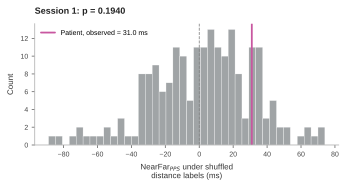

In [60]:
config.N_BOOT = 200 # as many as you want :)
r_h4 = h4.run(clin)


## H5. Does the patient's PPS boundary shift with speed, and differently from his control?

**Test A** asks whether the patient's boundary shifts with speed at all. His
slow and fast labels are shuffled many times to see how large a shift appears
by chance, and his real shift is compared with that.

**Test B** asks whether his shift differs from PA002's. Each person's trials
are resampled many times, and the difference between their shifts is
recalculated each time.

Test B is reported even if Test A fails. In that case its result comes with
a note that the patient showed no reliable shift to compare.

Patient session: 1 (the only one recorded)
Control session:                 1

Boundaries per participant and speed
  fitted with the H1a boundary sigmoid: plateaus fixed from the data, midpoint and slope estimated

  expectancy_model    2 of  2 fits sound,  1 participant(s) with both speeds

expectancy_model: 1 boundary pair(s), no group test
Boundaries per participant and speed
  fitted with the H1a boundary sigmoid: plateaus fixed from the data, midpoint and slope estimated

  expectancy_model    2 of  2 fits sound,  1 participant(s) with both speeds

expectancy_model: 1 boundary pair(s), no group test
Patient Delta_PPS = 0.947
Control Delta_PPS = 0.109
Observed D_PPS    = 0.838   (patient minus control)

--- Test A: does the patient show any Delta_PPS? ---
  observed Delta_PPS = 0.947
  permutation p      = 0.5319
  Test A supported   = False

--- Test B: does the patient differ from the matched control? ---
  Note: Test A did not pass. Any difference below is a difference from a p

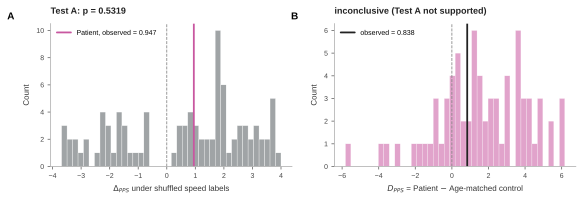


patient session used: 1


In [61]:
config.N_BOOT = 200 #idem
r_h5 = h5.run(clin, correction=CORRECTION)

print()
print("patient session used:", clin.patient_session)

## H6. Is his collision-boundary shift altered?

Same two-test structure on the Hit-or-Miss task. Requires H5 to have run.

Patient session: 1
Control session: 1

Patient Delta_coll = -2.04 cm
Control Delta_coll = -4.49 cm
Observed D_coll    = 2.45 cm

--- Test A: does the patient show any Delta_coll? ---
  observed Delta_coll = -2.04 cm
  permutation p       = 0.7512
  Test A supported    = False

Test A did not pass, so Test B is NOT run.
  saved: figures/h6_patient_collision.svg
  saved: figures/h6_patient_collision.pdf


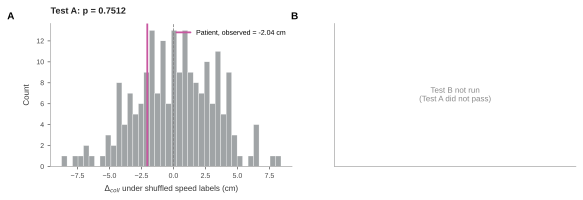

In [62]:
r_h6 = h6.run(clin)

# 6. Aim 3: Do the two tasks read out from the same estimate?

## H7a. Across the young controls

Three Spearman correlations between each participant's speed-driven PPS shift
and a collision measure, with exact one-sided permutation p values.

Participants: those in `boundaries` (H2) who also have collision trials. The
patient and matched controls are removed inside `h7a`. With n participants the
smallest reachable one-sided p is 1/n!, which is .0083 at n = 5.

H7a: correction level 'expectancy_model', session 1

H7a: no collision trials, dropped from all three tests:
  P010

H7a: 5 young controls with both measures

subject  delta_pps  delta_coll  accuracy  near_boundary_accuracy  carryover_cm
   P002      0.306       1.327     0.838                   0.799         1.442
   P003        NaN       1.509     0.909                   0.888        -0.533
   P008     -0.517       3.503     0.845                   0.803         1.189
   P009      0.910      -1.234     0.896                   0.876         1.829
   P011     -0.603       2.092     0.878                   0.842         1.623

H7a.1

rho                             -0.8
p_one_sided                   0.9583
n                                  4
n_perm                            24
exact                           True
classification    opposite direction

H7a.2 (primary)

rho                                                0.2
p_one_sided                                     0.4583
n        

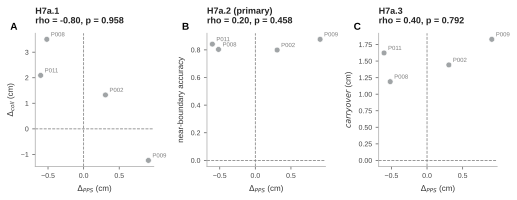

H7a summary

             hypothesis  rho     p                       classification
                  H7a.1 -0.8 0.958                   opposite direction
  H7a.2 (near, primary)  0.2 0.458 predicted direction, not significant
H7a.2 (overall, descr.)  0.2 0.458 predicted direction, not significant
                  H7a.3  0.4 0.792                   opposite direction


In [63]:
r_h7a = h7a.run(boundaries, clin, correction=CORRECTION)

## H7b. Within the clinical pair

The criterion is whether the patient deviates from his control in the same
direction on both tasks, so each bootstrap draw has to hold a PPS deviation and
a collision deviation from the same resample.

`h7b.run` merges H5's PPS bootstrap with a separate collision bootstrap on the
draw number. Draws with the same number come from different resamples, so this
does not pair them. `paired.run` (`h7b_paired`) resamples both tasks in the same
draw, which is the criterion as stated. Both are run below.

H7b: observed deviations (patient minus control)

    measure  patient  control  difference
      D_PPS    0.947    0.109       0.838
     D_coll   -2.045   -4.491       2.446
      D_acc    0.756    0.859      -0.103
  D_nearacc    0.717    0.817      -0.100
D_carryover   -4.579   -5.071       0.492

H7b paired bootstrap samples: 200

H7b.1

p_both_negative        0.069444
p_both_positive        0.513889
p_d1neg_d2pos          0.152778
p_d1pos_d2neg          0.263889
classification     inconclusive

H7b.2

p_both_negative        0.222222
p_both_positive        0.013889
p_d1neg_d2pos               0.0
p_d1pos_d2neg          0.763889
classification     inconclusive

H7b.3

p_pps_neg_carry_pos        0.111111
p_pps_pos_carry_neg        0.333333
p_both_negative            0.111111
p_both_positive            0.444444
classification         inconclusive

H7b.2 (descriptive: overall accuracy)

p_both_negative        0.222222
p_both_positive             0.0
p_d1neg_d2pos               0.0
p_d

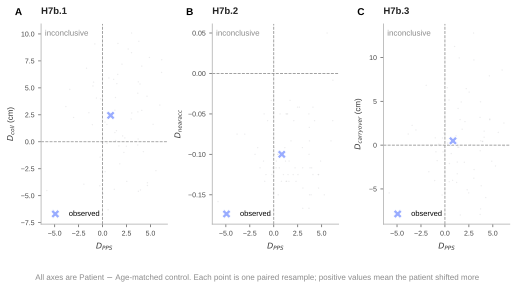

H7b summary

             hypothesis classification
                  H7b.1   inconclusive
  H7b.2 (near, primary)   inconclusive
H7b.2 (overall, descr.)   inconclusive
                  H7b.3   inconclusive


In [64]:
r_h7b = h7b.run(clin, r_h5)

In [65]:
paired_result = paired.run(
    clin,
    ball_radius_cm=BALL_RADIUS_CM,
    correction=CORRECTION,
    expectancy_degree=DEGREE,
    pps_index="nearfar",
    n_boot=500,
)
paired.report(paired_result)

/opt/anaconda3/envs/pps/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:2385: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))
/opt/anaconda3/envs/pps/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/envs/pps/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:2385: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))
/opt/anaconda3/envs/pps/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/envs/pps/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identif

H7b, paired bootstrap: PT001 against PA002, 500 draws, PPS index = nearfar

  observed  D_PPS  = -3.96 ms   (+9.89 vs +13.85)
            D_coll = +1.67 cm      (-2.98 vs -4.66)

                        quadrant                      meaning  proportion  usable_draws  failed_draws
                   both negative concordant under-calibration       0.145           497             3
                   both positive  concordant over-calibration       0.364           497             3
PPS negative, collision positive                   discordant       0.326           497             3
PPS positive, collision negative                   discordant       0.165           497             3

  3 of 500 draws produced no usable boundary in one task or the other.

  Inconclusive: the largest quadrant holds 0.364 of draws, below the 0.95 criterion.


In [66]:
draws = paired_result["draws"]
print(draws[["pps_patient", "pps_control", "d_pps"]].describe().round(2))

       pps_patient  pps_control   d_pps
count       500.00       500.00  500.00
mean         16.82        14.75    2.07
std          67.29        67.59   93.76
min        -230.91      -160.71 -350.83
25%         -29.01       -29.68  -59.14
50%          14.97        13.21    5.36
75%          61.59        60.00   62.68
max         209.53       225.41  297.21


# 7. Summary

One row per hypothesis, read straight off the results objects above. Anything
that reads "skipped" means its section did not run in this kernel.

In [67]:
def outcome(results, *keys, default="not run"):
    """Read the first key present, so a renamed field shows up as missing."""
    for key in keys:
        if isinstance(results, dict) and key in results:
            return results[key]
    return default


summary = pd.DataFrame([
    {"hypothesis": "H1",    "outcome": outcome(result_h1, "supported")},
    {"hypothesis": "H1a",   "outcome": f"{outcome(r_h1a, 'n_supported')}"
                                       f"/{outcome(r_h1a, 'n_total')}"},
    {"hypothesis": "H2",    "outcome": f"{boundaries['delta_pps'].notna().sum()}"
                                       f" of {len(boundaries)} estimable"},
    {"hypothesis": "H3",    "outcome": outcome(r_h3, "supported")},
    {"hypothesis": "H4",    "outcome": outcome(r_h4, "h4_supported_overall")},
    {"hypothesis": "H5",    "outcome": outcome(r_h5, "h5_classification")},
    {"hypothesis": "H6",    "outcome": outcome(r_h6, "h6_classification")},
    {"hypothesis": "H7a.1", "outcome": r_h7a["h7a_1"]["classification"]},
    {"hypothesis": "H7a.2", "outcome": r_h7a["h7a_2_near"]["classification"]},
    {"hypothesis": "H7a.3", "outcome": r_h7a["h7a_3"]["classification"]},
    {"hypothesis": "H7b.1", "outcome": r_h7b["h7b_1"]["classification"]},
    {"hypothesis": "H7b.2", "outcome": r_h7b["h7b_2_near"]["classification"]},
    {"hypothesis": "H7b.3", "outcome": r_h7b["h7b_3"]["classification"]},
])

display(summary)

,hypothesis,outcome
0,H1,True
1,H1a,5/7
2,H2,5 of 6 estimable
3,H3,True
4,H4,False
5,H5,inconclusive (Test A not supported)
6,H6,Test A failed; Test B not run
7,H7a.1,opposite direction
8,H7a.2,"predicted direction, not significant"
9,H7a.3,opposite direction


# Appendix. Sensitivity checks

Kept out of the main path so the reading order above stays one analysis deep.
Each cell answers a question a reader could reasonably ask about a choice made
earlier.

## A.1 Does the manual review change the boundary fits?

Preregistered rules alone against preregistered plus manual. A participant
whose `estimable` flag flips between the two is one whose boundary depends on
trials removed by hand, and belongs in the write-up as such.

In [68]:
rows = []

for subject in sorted(young.marked["subject"].dropna().unique()):
    one = young.marked[young.marked["subject"].eq(subject)]

    rules = {
        "preregistered": one[
            one["usable"] | one["exclusion_reason"].eq("manual review")
        ],
        "plus_manual": one[one["usable"]],
    }

    for label, frame in rules.items():
        fit = ex.vt_shape(frame)

        if fit.empty:
            continue

        row = fit.iloc[0]
        rows.append({
            "subject": subject, "rule": label,
            "k": row["k"], "x_c": row["x_c"], "se_x_c": row["se_x_c"],
            "estimable": row["estimable"],
        })

print(
    pd.DataFrame(rows).round(2)
    .pivot(index="subject", columns="rule").to_string()
)

                  k                       x_c                    se_x_c                 estimable              
rule    plus_manual preregistered plus_manual preregistered plus_manual preregistered plus_manual preregistered
subject                                                                                                        
P002          -0.62         -0.62        4.41          4.41        1.57          1.57       False         False
P003         -19.96        -19.96        3.93          3.93   266387.58     266387.58       False         False
P005         -40.16        -40.16        4.99          4.99        0.05          0.05       False         False
P008          -0.67         -0.67        2.00          2.00        1.94          1.94       False         False
P009          -1.54         -1.54        4.03          4.03        0.74          0.74        True          True
P010          -1.81         -1.81        4.90          4.90        0.65          0.65        True       

## A.2 Does the result depend on the baseline correction?

The same profile under each correction. A vertical offset between them is
expected, since the tactile distribution is right-skewed. A change in shape is
the thing to worry about, because it means the profile depends on an estimator
choice rather than on the data.

In [69]:
for correction in ["delay_matched", "expectancy_model", "fastest_tactile"]:
    one = h1.facilitation_profile(
        young.trials, estimator="median",
        correction=correction, expectancy_degree=DEGREE,
    )
    group = h1.group_summary(h1.subject_profile(one))

    print(f"\n=== {correction} ===")
    print(group.round(1).to_string(index=False))


=== delay_matched ===
 position_rank  group_mean  group_sd  n  group_sem
           1.0        52.2      52.3  9       17.4
           2.0        64.8      45.2  9       15.1
           3.0        64.1      44.7  9       14.9
           4.0        25.9      35.2  9       11.7
           5.0        15.6      33.5  9       11.2
           6.0        25.3      29.4  9        9.8
           7.0        -3.3      39.8  9       13.3

=== expectancy_model ===
 position_rank  group_mean  group_sd  n  group_sem
           1.0        61.2      43.0  9       14.3
           2.0        67.3      36.7  9       12.2
           3.0        59.6      29.8  9        9.9
           4.0        47.4      32.5  9       10.8
           5.0        28.9      21.9  9        7.3
           6.0        29.2      29.1  9        9.7
           7.0        17.3      37.7  9       12.6

=== fastest_tactile ===
 position_rank  group_mean  group_sd  n  group_sem
           1.0         8.4      16.9  9        5.6
        

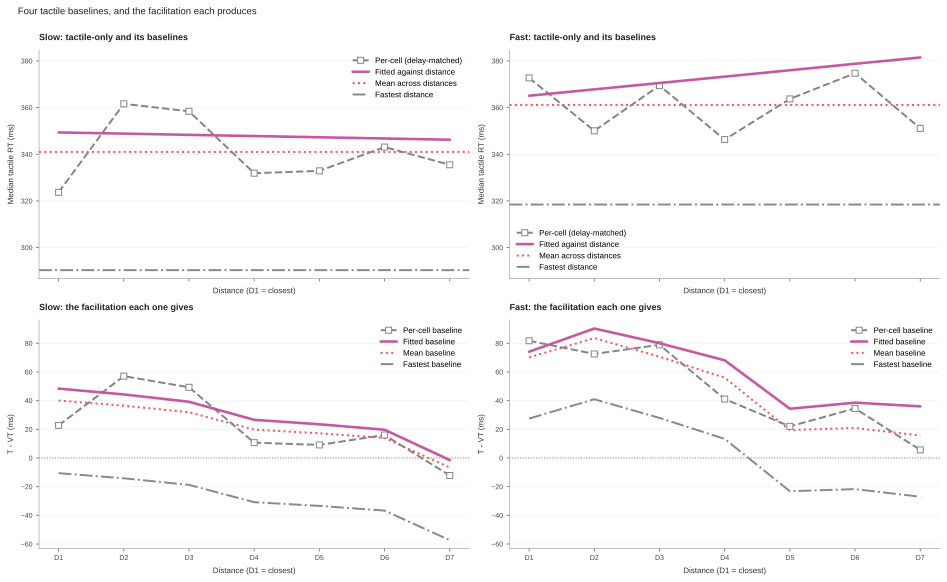

saved /Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/results/young_controls/data_exclusions/baseline_comparison_young.png


PosixPath('/Users/pamelavandenenden/Desktop/PPS/05_analysis/01_behavioral_analyses/results/young_controls/data_exclusions/baseline_comparison_young.png')

In [70]:
fig = qc.plot_baselines(young.marked, statistic="median", degree=DEGREE)
plt.show()
save(fig, "baseline_comparison_young")

Every correction for H1, H2 and the clinical pair, through
`baseline_robustness`. H1 uses the H1 sample (`trials_h1`), H2 the H2 sample
(`trials_h2`).

In [71]:
BR_CORRECTIONS = [
    "delay_matched", "expectancy_model",
    "fastest_tactile", "fastest_n_tactile", "noel_endpoints",
]

clinical_trials = pd.concat(
    [coh[name].trials for name in CLINICAL], ignore_index=True,
)

br_h1 = br.facilitation_under_each(
    trials_h1, corrections=BR_CORRECTIONS, expectancy_degree=DEGREE,
)
br_h2_group, br_h2_subjects = br.boundaries_under_each(
    trials_h2, corrections=BR_CORRECTIONS, expectancy_degree=DEGREE,
)
br_clinical = br.clinical_under_each(
    clinical_trials, patient=PATIENT, control=MATCHED_CONTROL,
    corrections=BR_CORRECTIONS, expectancy_degree=DEGREE,
)

H1 under each baseline correction

       correction    index  n    mean  ci_low  ci_high    W     p
    delay_matched  overall  9  34.951  21.082   49.283 45.0 0.002
    delay_matched near-far  9  47.535  20.736   76.970 42.0 0.010
 expectancy_model  overall  9  44.410  30.920   59.830 45.0 0.002
 expectancy_model near-far  9  40.975   7.918   72.128 39.0 0.027
  fastest_tactile  overall  9 -11.715 -21.058   -3.507  7.0 0.973
  fastest_tactile near-far  9  46.612  33.626   59.776 45.0 0.002
fastest_n_tactile  overall  9 -47.834 -63.739  -35.833  0.0 1.000
fastest_n_tactile near-far  9  46.612  33.626   59.776 45.0 0.002
   noel_endpoints  overall  9   4.930  -6.203   13.352 30.0 0.213
   noel_endpoints near-far  9  46.612  33.626   59.776 45.0 0.002

  The direction is what matters. A mean that stays positive under every correction is robust to the choice; one that changes sign is not.
Boundaries per participant and speed
  fitted with the H1a boundary sigmoid: plateaus fixed from the

## A.3 Mean against median as the cell estimator

At four tactile trials per cell the median is the noisier of the two, so the
preregistration names the mean baseline as a sensitivity analysis.

In [72]:
print(h1.compare_estimators(young.trials, correction=CORRECTION).round(1).to_string(index=False))

subject  near_mean_estimator  far_mean_estimator  nearfar_mean_estimator  near_median_estimator  far_median_estimator  nearfar_median_estimator  mean_minus_median
   P002                 42.7               -24.1                    66.8                   70.7                 -15.2                      85.9              -19.1
   P003                 15.6                25.3                    -9.7                   19.4                  30.3                     -10.9                1.2
   P005                 14.0                67.8                   -53.8                   21.0                  88.8                     -67.8               13.9
   P008                 38.3                13.7                    24.6                   51.1                  23.8                      27.3               -2.7
   P009                113.1                 4.5                   108.6                  123.7                  40.0                      83.8               24.8
   P010               

## A.4 Which cohorts are loaded

Run this after any change to section 1, before trusting anything below it.

In [73]:
print(list(coh.keys()))

for name, cohort in coh.items():
    usable = int(cohort.marked["usable"].fillna(False).sum())
    print(f"  {name:8s} {usable:5d} usable, {cohort.subject_ids}")

['young', 'matched', 'patient']
  young     2392 usable, ['P002', 'P003', 'P005', 'P008', 'P009', 'P010', 'P011', 'T001', 'T002']
  matched    402 usable, ['PA001', 'PA002']
  patient    195 usable, ['PT001']


## A.5 Does the delay variable matter?

Refits the baseline with `ex.expectancy_baseline` against each candidate column
and compares the fitted values cell by cell. At `degree=1` the two agree to a
fraction of a millisecond, because the foreperiod is affine in rank within each
speed and the interaction term absorbs the different scaling. At `degree=2`
they do not, and `tactile_foreperiod_ms` is then the column to use.

Run this at both degrees before reporting anything fitted at degree 2.

In [74]:
def baseline_under(trials, delay_column, degree):
    """Fitted tactile baseline per cell, under one delay column."""
    fitted, _ = ex.expectancy_baseline(
        trials, degree=degree, delay_column=delay_column,
    )
    return fitted.set_index(["subject", "speed", "position_rank"])[
        "tactile_baseline_ms"
    ]


for degree in [1, 2]:
    by_rank = baseline_under(young.trials, "position_rank", degree)
    by_foreperiod = baseline_under(young.trials, "tactile_foreperiod_ms", degree)

    difference = (by_rank - by_foreperiod).dropna()

    print(
        f"degree {degree}: {len(difference)} cells, "
        f"max absolute difference {difference.abs().max():.3f} ms"
    )

degree 1: 126 cells, max absolute difference 0.699 ms
degree 2: 126 cells, max absolute difference 22.339 ms


## A.6 How far the ball had travelled when each answer came

Young controls after rules 5 and 6; the patient and PA002 after rule 5.

panel             Age-matched control  Patient  Young controls
trial_type speed                                              
clear_hit  fast                  2.25     2.37            2.71
           slow                  3.23     3.83            3.85
clear_miss fast                  1.94     2.40            2.51
           slow                  3.06     3.58            3.85
near_hit   fast                  1.70     2.13            2.42
           slow                  2.91     3.18            3.52
near_miss  fast                  1.94     2.35            2.35
           slow                  2.27     3.44            3.66
  saved: figures/response_fans_all.svg
  saved: figures/response_fans_all.pdf


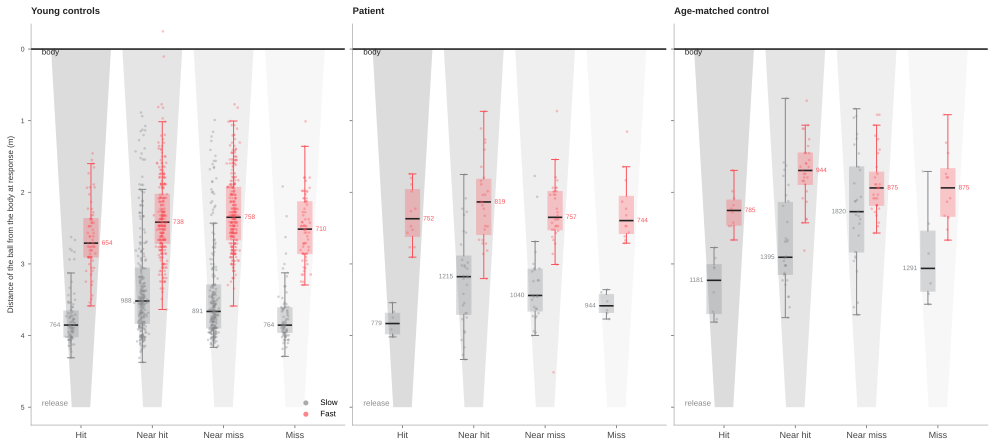

In [75]:
young_usable = young.collision[young.collision["usable"].fillna(False)]

fig, fans = ft.plot_response_fans(
    [
        ("Young controls", young_usable, None),
        ("Patient", clin.collision_trials, PATIENT),
        ("Age-matched control", clin.collision_trials, MATCHED_CONTROL),
    ],
    slow_colour=style.SLOW, fast_colour=style.FAST,
    save_as="response_fans_all",
)

panel             P002  P003  P005  P008  P009  P011
trial_type speed                                    
clear_hit  fast   2.86  2.49  3.10  2.52  2.43  2.43
           slow   4.02  3.91  4.05  3.70  3.82  3.56
clear_miss fast   2.76  2.83  2.56  2.18  2.52  1.94
           slow   3.98  3.88  3.93  3.62  3.92  3.56
near_hit   fast   2.51  2.42  2.76  2.28  2.47  1.89
           slow   3.83  3.27  3.75  3.39  3.48  3.38
near_miss  fast   2.54  2.37  2.51  2.13  2.67  1.93
           slow   3.91  3.32  3.79  3.06  3.81  3.42
  saved: figures/response_fans_young_by_subject.svg
  saved: figures/response_fans_young_by_subject.pdf


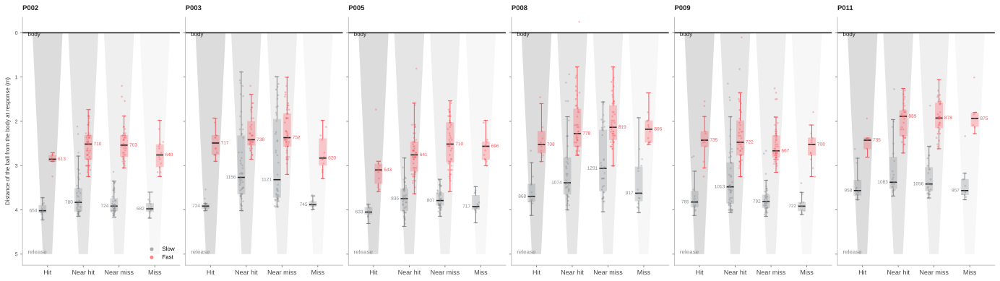

In [76]:
people = sorted(young_usable["subject"].unique())

fig, fans_by_subject = ft.plot_response_fans(
    [(s, young_usable, s) for s in people],
    slow_colour=style.SLOW, fast_colour=style.FAST,
    panel_size=(3.2, 5.4),
    save_as="response_fans_young_by_subject",
)

In [77]:
d = clin.collision_trials[
    (clin.collision_trials["subject"] == "PT001")
    & (clin.collision_trials["trial_type"] == "near_hit")
    & clin.collision_trials["usable"].fillna(False)
].copy()

d["correct"] = d["response_hit"].astype(bool) == (
    d["correct_response"].astype("string").str.upper() == "HIT"
)

for speed in ["slow", "fast"]:
    cell = d[d["speed"] == speed]

    right = cell.loc[cell["correct"], "rt_ms"]
    wrong = cell.loc[~cell["correct"], "rt_ms"]

    if len(right) < 5 or len(wrong) < 5:
        print(f"{speed}: too few in one group")
        continue

    test = stats.mannwhitneyu(right, wrong, alternative="two-sided")

    print(f"{speed}: correct {right.median():.0f} ms (n={len(right)}), "
          f"wrong {wrong.median():.0f} ms (n={len(wrong)}), "
          f"U = {test.statistic:.0f}, p = {test.pvalue:.3f}")

slow: correct 1139 ms (n=21), wrong 1346 ms (n=11), U = 73, p = 0.096
fast: correct 792 ms (n=15), wrong 819 ms (n=12), U = 89, p = 0.981


In [78]:
for subject in ["PT001", "PA002"]:
    d = clin.collision_trials[
        (clin.collision_trials["subject"] == subject)
        & (clin.collision_trials["trial_type"] == "near_hit")
        & clin.collision_trials["usable"].fillna(False)
    ].copy()

    d["correct"] = d["response_hit"].astype(bool) == (
        d["correct_response"].astype("string").str.upper() == "HIT")
    d = ft.flight_position(d)

    r = stats.spearmanr(d["flight_fraction"], d["correct"].astype(int))
    print(f"{subject}: rho {r.statistic:+.2f}, p = {r.pvalue:.3f}, n = {len(d)}")

PT001: rho -0.20, p = 0.121, n = 59
PA002: rho -0.30, p = 0.020, n = 59


## A.7 Bootstrap intervals on the patient's collision boundary

PT001: boundary uncertainty
  200 draws, 71 slow and 85 fast trials

  quantity  observed  boot_median  ci_low  ci_high  width  p_below_zero  usable_draws  failed_draws
  PSE slow    -3.768       -3.776  -7.118   -0.271  6.847         0.980           200             0
  PSE fast    -6.751       -6.312 -12.705   -1.584 11.121         1.000           200             0
Delta_coll    -2.983       -2.347  -9.352    2.447 11.799         0.805           200             0
slope slow    -0.170       -0.176  -0.338   -0.109  0.228         1.000           200             0
slope fast    -0.105       -0.109  -0.180   -0.067  0.113         1.000           200             0

  Delta_coll = -2.98 cm, 95% interval [-9.35, 2.45], 80.5% of draws negative.
  The interval spans zero, so the direction of the shift is not established for this participant.
  saved: figures/pse_uncertainty_patient.svg
  saved: figures/pse_uncertainty_patient.pdf


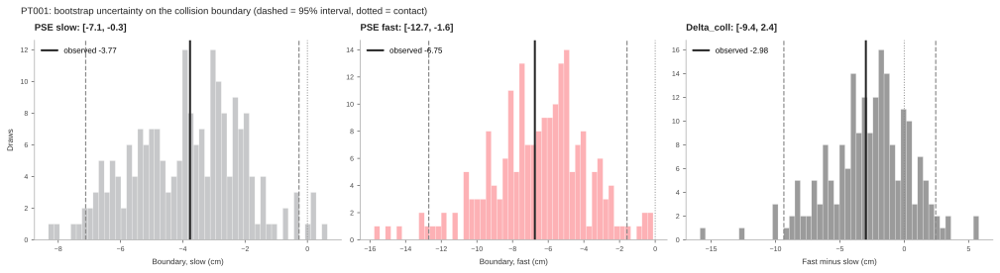

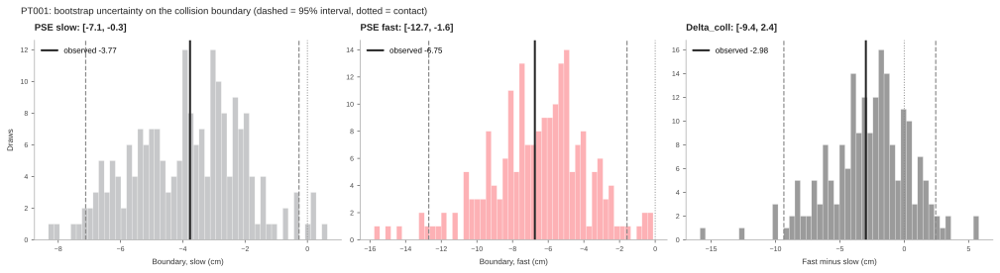

In [79]:
pse_result = pu.estimate(
    clin.collision_trials, PATIENT, ball_radius_cm=BALL_RADIUS_CM,
)
pu.report(pse_result)
pu.plot(pse_result, save_as="pse_uncertainty_patient")

## A.8 Likelihood-ratio tests of the two psychometric curves, per participant

Whether speed shifts the curve, and whether it changes its slope, tested on
each participant's own trials.

In [80]:
lr_young = cc.compare_all(young.collision, ball_radius_cm=BALL_RADIUS_CM)

print()
lr_clinical = cc.compare_all(
    clin.collision_trials, subjects=[PATIENT, MATCHED_CONTROL],
    ball_radius_cm=BALL_RADIUS_CM,
)

subject  n_trials  shift_lr  shift_p  slope_lr  slope_p
   P002       229    0.4454   0.5045    0.5722   0.4494
   P003       231    1.0874   0.2970   10.8171   0.0010
   P005       233   22.6176   0.0000    4.4781   0.0343
   P008       232    3.5867   0.0582   10.1676   0.0014
   P009       231    0.4346   0.5097   11.0190   0.0009
   P011       156    1.5289   0.2163    1.3948   0.2376

  boundary moved with speed in 1 of 6
  slope differed with speed in 4 of 6

  These are per-participant tests on all of that person's
  trials, not a group test. A participant can show a large
  boundary shift and still fail here if neither curve was
  well determined.

subject  n_trials  shift_lr  shift_p  slope_lr  slope_p
  PT001       156    0.4032   0.5254    2.1546   0.1421
  PA002       156    4.6141   0.0317   10.5364   0.0012

  boundary moved with speed in 1 of 2
  slope differed with speed in 1 of 2

  These are per-participant tests on all of that person's
  trials, not a group test. A p